# Radiomics Feature Extraction & AI Based Classification of Brain Tumors (MRI)


**Pipeline**

| Step | What happens |
|---|---|
| 1 | Install libraries (PyRadiomics, SimpleITK, XGBoost, SHAP) |
| 2 | Configuration (paths, split ratio, number of features …) |
| 3 | Extract the Figshare `.zip` files and read every `.mat` file (image, tumor mask, label, patient ID) |
| 4 | Exploratory data analysis (class distribution, image sizes, tumor area, sample images with masks) |
| 5 | **Patient-level** train / test split (no patient appears in both sets → no data leakage) |
| 6 | Radiomics feature extraction with PyRadiomics (IBSI-compliant): shape, first-order, GLCM, GLRLM, GLSZM, GLDM, NGTDM |
| 6b | Extra features: peritumoral ring radiomics, tumor-location features, deep features (ImageNet ResNet-50 on the tumor crop) |
| 7 | Feature analysis on the training set (statistics, box plots, correlation, PCA / t-SNE) |
| 8 | Feature selection (variance → correlation filter → ANOVA-F top-K), with K and the correlation threshold tuned by cross-validation |
| 9 | Training 7 classifiers (incl. a soft-voting ensemble) with 5-fold **patient-grouped** cross-validation → training & validation results |
| 10 | Test-set evaluation: metrics table, confusion matrices, ROC & PR curves, patient-level results |
| 11 | Interpretation: feature importance, SHAP, permutation importance, misclassified examples |
| 12 | Save every table / figure to Google Drive |



## 1. Install libraries

In [ ]:
# PyRadiomics: the PyPI release does not build on Colab's Python 3.12, so install from the official GitHub source.
!pip install -q SimpleITK pywavelets xgboost shap h5py openpyxl
try:
    import radiomics
except ImportError:
    !pip install -q git+https://github.com/AIM-Harvard/pyradiomics.git

import importlib
importlib.invalidate_caches()
try:
    import radiomics
    USE_PYRADIOMICS = True
    print("PyRadiomics version:", radiomics.__version__)
except ImportError:
    USE_PYRADIOMICS = False
    print("PyRadiomics could not be installed -> the built-in fallback extractor (first-order, shape, GLCM) will be used.")

PyRadiomics version: 3.1.1.dev111+g8ed579383


## 2. Imports and configuration

In [ ]:
import os, glob, zipfile, time, json, warnings, logging, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py, scipy.io
from scipy import stats
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, f_classif
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold, cross_validate,
                                     cross_val_predict, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, cohen_kappa_score, matthews_corrcoef, confusion_matrix,
                             classification_report, roc_curve, auc, precision_recall_curve, average_precision_score)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
logging.getLogger("radiomics").setLevel(logging.ERROR)

# ============================ CONFIGURATION ============================
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_ROOT = "/content/drive/MyDrive"

# Folder (or .zip) in Google Drive holding the Figshare .mat files. If it is not found, the notebook searches
# MyDrive for a "brainTumorDataPublic..." folder/zip, and finally asks you to upload a .zip from your computer.
DATA_DIR    = os.environ.get("FIGSHARE_DIR", DRIVE_ROOT)
WORK_DIR    = os.environ.get("WORK_DIR",     "/content/figshare_work")                # fast local disk for extraction
RESULTS_DIR = os.environ.get("RESULTS_DIR",  f"{DRIVE_ROOT}/radiomics_results")       # all tables & figures saved here

SEED            = 42
TEST_SIZE       = 0.20    # fraction of PATIENTS held out for testing
N_FOLDS         = 5       # patient-grouped cross-validation folds on the training set
K_FEATURES      = 50      # number of features kept by the selector (overwritten by tuning if TUNE_SELECTION)
CORR_THRESHOLD  = 0.90    # drop one of every pair of features with |Pearson r| above this
HARMONIZE_SIZE  = 512     # up-sample the 256x256 slices to 512x512 so shape features are comparable (None = off)
ENABLE_FILTERS  = False   # True = also extract Wavelet + LoG features (~5x slower, ~900 features)
BIN_WIDTH       = 10      # gray-level discretization after z-score normalization (scale 100)
N_JOBS          = -1      # parallel workers for feature extraction
MAX_SLICES      = None    # e.g. 300 for a quick trial run; None = use all 3,064 slices

# ---- extra features (Section 6b) — these are what push accuracy above the plain-radiomics baseline ----
ADD_PERITUMORAL = True    # radiomics of a ring of tissue around the tumor (Cheng et al. 2015 showed this helps)
PERI_RADIUS     = 12      # ring width in pixels (on the 512x512 grid)
ADD_LOCATION    = True    # where the tumor sits in the head (pituitary = central, meningioma = near the edge)
ADD_DEEP        = True    # 2048 deep features from an ImageNet-pretrained ResNet-50 applied to the tumor crop
TUNE_SELECTION  = True    # choose K_FEATURES and CORR_THRESHOLD by patient-grouped CV on the training set

CLASS_NAMES  = {1: "Meningioma", 2: "Glioma", 3: "Pituitary"}
CLASS_ORDER  = ["Meningioma", "Glioma", "Pituitary"]
CLASS_COLORS = {"Meningioma": "#4C72B0", "Glioma": "#DD8452", "Pituitary": "#55A868"}
# =======================================================================

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

FIG_DIR = os.path.join(RESULTS_DIR, "figures"); TAB_DIR = os.path.join(RESULTS_DIR, "tables")
for d in (WORK_DIR, RESULTS_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"))
    plt.show()

def savetab(df, name, index=True):
    df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=index)

print("Running in Colab:", IN_COLAB)
print("DATA_DIR   :", DATA_DIR)
print("RESULTS_DIR:", RESULTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
DATA_DIR   : /content/drive/MyDrive
RESULTS_DIR: /content/drive/MyDrive/radiomics_results


## 3. Extract the files and load images, masks, labels and patient IDs
Each `.mat` file holds one 2-D contrast-enhanced T1 slice with `cjdata.image`, `cjdata.tumorMask`, `cjdata.label` (1 = meningioma, 2 = glioma, 3 = pituitary) and `cjdata.PID` (patient ID).

In [ ]:
EXTRACT_DIR = os.path.join(WORK_DIR, "mat")
os.makedirs(EXTRACT_DIR, exist_ok=True)

def extract_zips_recursive(src, dst_dir):
    # Extract src (a .zip, or every zip in a folder), then any zips found inside (handles the single 1512427.zip download).
    done = set()
    pending = [src] if src.lower().endswith(".zip") else sorted(glob.glob(os.path.join(src, "**", "*.zip"), recursive=True))
    while pending:
        z = pending.pop(0)
        if z in done:
            continue
        print("Extracting", os.path.basename(z))
        with zipfile.ZipFile(z) as zf:
            zf.extractall(dst_dir)
        done.add(z)
        pending += [p for p in sorted(glob.glob(os.path.join(dst_dir, "**", "*.zip"), recursive=True)) if p not in done]

def list_mat(folder):
    return [p for p in glob.glob(os.path.join(folder, "**", "*.mat"), recursive=True)
            if "cvind" not in os.path.basename(p).lower()]

def has_data(p):
    if os.path.isfile(p):
        return p.lower().endswith(".zip")
    return os.path.isdir(p) and bool(list_mat(p) or glob.glob(os.path.join(p, "**", "*.zip"), recursive=True))

def locate_data(path):
    if has_data(path):
        return path
    print(f"Not found: {path}\nSearching Google Drive for the Figshare data ...")
    for pat in ["brainTumorDataPublic*", "*/brainTumorDataPublic*", "*figshare*", "*/*figshare*", "1512427*", "*/1512427*"]:
        for c in sorted(glob.glob(os.path.join(DRIVE_ROOT, pat))):
            if has_data(c):
                print("Found:", c)
                return c
    if IN_COLAB:
        from google.colab import files
        print("Data not found in Drive. Please upload a .zip of the folder (right-click folder -> Send to -> Compressed (zipped) folder).")
        up_dir = os.path.join(WORK_DIR, "upload"); os.makedirs(up_dir, exist_ok=True)
        for name, content in files.upload().items():
            with open(os.path.join(up_dir, name), "wb") as fh:
                fh.write(content)
        return up_dir
    raise FileNotFoundError(f"No Figshare .mat or .zip files found at {path}")

mat_files = list_mat(EXTRACT_DIR)
if not mat_files:
    DATA_DIR = locate_data(DATA_DIR)
    print("Using data from:", DATA_DIR)
    if os.path.isdir(DATA_DIR) and list_mat(DATA_DIR):
        mat_files = list_mat(DATA_DIR)                       # already-extracted .mat files: read them directly
    else:
        extract_zips_recursive(DATA_DIR, EXTRACT_DIR)
        mat_files = list_mat(EXTRACT_DIR)

def _num(p):
    s = os.path.splitext(os.path.basename(p))[0]
    return int(s) if s.isdigit() else 10**9
mat_files = sorted(set(mat_files), key=lambda p: (_num(p), p))
assert mat_files, f"No .mat files found in {DATA_DIR}. Check DATA_DIR."
print(f"Found {len(mat_files)} .mat slice files")

Using data from: /content/drive/MyDrive
Found 1532 .mat slice files


In [ ]:
def load_mat(path):
    # Returns image (float32), mask (uint8), label (int), patient ID (str). Handles MATLAB v7.3 (HDF5) and older formats.
    try:
        with h5py.File(path, "r") as f:
            cj = f["cjdata"]
            label = int(np.array(cj["label"]).squeeze())
            pid = "".join(chr(int(c)) for c in np.array(cj["PID"]).flatten()).strip()
            img = np.array(cj["image"]).T.astype(np.float32)      # HDF5 stores MATLAB arrays transposed
            mask = (np.array(cj["tumorMask"]).T > 0).astype(np.uint8)
    except OSError:
        cj = scipy.io.loadmat(path, squeeze_me=True, struct_as_record=False)["cjdata"]
        label, pid = int(cj.label), str(cj.PID).strip()
        img, mask = np.asarray(cj.image, np.float32), (np.asarray(cj.tumorMask) > 0).astype(np.uint8)
    return img, mask, label, pid

rows = []
for p in mat_files:
    img, mask, label, pid = load_mat(p)
    rows.append(dict(file=p, slice_id=os.path.splitext(os.path.basename(p))[0], label=label,
                     tumor_type=CLASS_NAMES[label], PID=pid, height=img.shape[0], width=img.shape[1],
                     tumor_area_px=int(mask.sum()), img_min=float(img.min()), img_max=float(img.max())))
meta = pd.DataFrame(rows)

# Remove slices whose mask is empty or too small for texture analysis
bad = meta["tumor_area_px"] < 20
if bad.any():
    print(f"Removing {bad.sum()} slice(s) with an empty / tiny tumor mask")
meta = meta[~bad].reset_index(drop=True)

if MAX_SLICES:
    meta = meta.groupby("tumor_type", group_keys=False).apply(
        lambda g: g.sample(min(len(g), MAX_SLICES // 3), random_state=SEED)).reset_index(drop=True)
    print(f"QUICK MODE: using {len(meta)} slices")

meta["y"] = meta["label"] - 1          # 0 = Meningioma, 1 = Glioma, 2 = Pituitary
print(f"Slices: {len(meta)} | Patients: {meta.PID.nunique()}")
display(meta.head())
savetab(meta.drop(columns=["file"]), "01_dataset_metadata", index=False)

Slices: 1532 | Patients: 163


,file,slice_id,label,tumor_type,PID,height,width,tumor_area_px,img_min,img_max,y
0,/content/drive/MyDrive/Brain Features Extracti...,1,1,Meningioma,100360,512,512,4569,0.0,3366.0,0
1,/content/drive/MyDrive/Brain Features Extracti...,2,1,Meningioma,100360,512,512,8630,0.0,3626.0,0
2,/content/drive/MyDrive/Brain Features Extracti...,3,1,Meningioma,100360,512,512,10511,0.0,3695.0,0
3,/content/drive/MyDrive/Brain Features Extracti...,4,1,Meningioma,100360,512,512,8897,0.0,4196.0,0
4,/content/drive/MyDrive/Brain Features Extracti...,5,1,Meningioma,100360,512,512,11250,0.0,3948.0,0


## 4. Exploratory data analysis

**Table 1 – Dataset summary**

,Slices,Patients,Mean_tumor_area_px,Median_tumor_area_px
tumor_type,,,,
Meningioma,705.0,79.0,4659.9,3992.0
Glioma,205.0,22.0,6936.4,5411.0
Pituitary,622.0,62.0,2066.4,1744.0
Total,1532.0,163.0,3911.5,2790.5


**Table 2 – Image sizes**

,height,width,Slices
0,256,256,15
1,512,512,1517


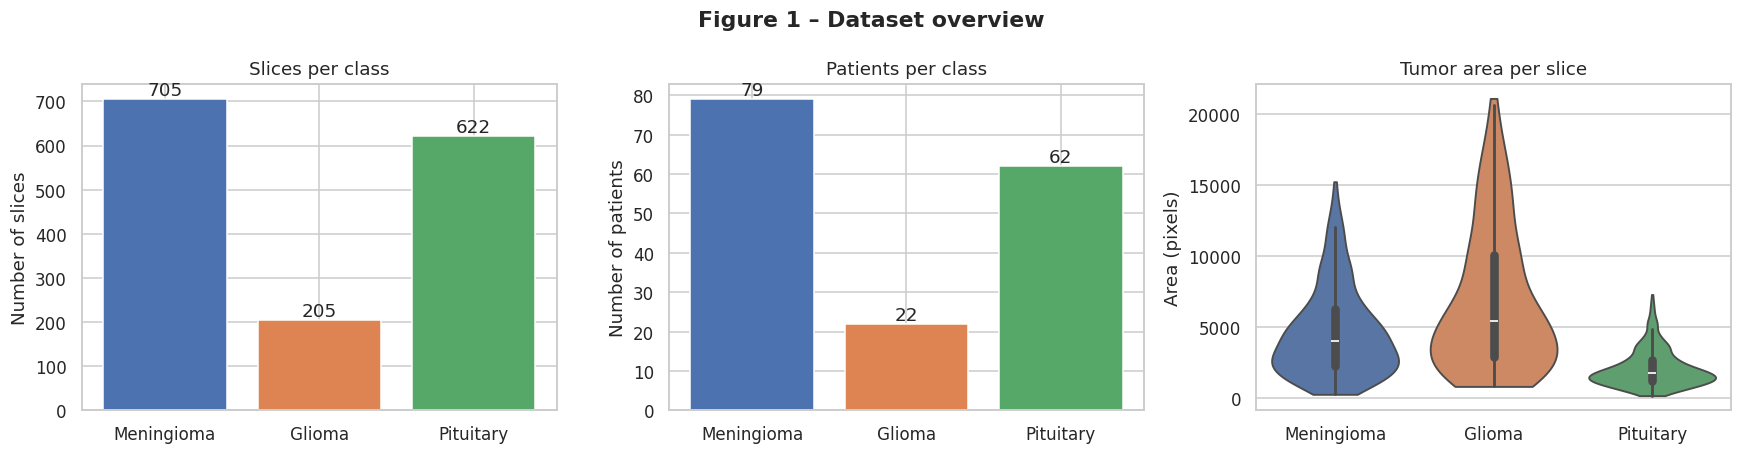

In [ ]:
summary = (meta.groupby("tumor_type")
           .agg(Slices=("slice_id", "count"), Patients=("PID", "nunique"),
                Mean_tumor_area_px=("tumor_area_px", "mean"), Median_tumor_area_px=("tumor_area_px", "median"))
           .reindex(CLASS_ORDER))
summary.loc["Total"] = [summary.Slices.sum(), meta.PID.nunique(), meta.tumor_area_px.mean(), meta.tumor_area_px.median()]
summary = summary.round(1)
display(Markdown("**Table 1 – Dataset summary**")); display(summary)
savetab(summary, "02_dataset_summary")

size_tab = meta.groupby(["height", "width"]).size().rename("Slices").reset_index()
display(Markdown("**Table 2 – Image sizes**")); display(size_tab)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
s = meta.tumor_type.value_counts().reindex(CLASS_ORDER)
ax[0].bar(s.index, s.values, color=[CLASS_COLORS[c] for c in s.index])
for i, v in enumerate(s.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Slices per class"); ax[0].set_ylabel("Number of slices")
pt = meta.groupby("tumor_type").PID.nunique().reindex(CLASS_ORDER)
ax[1].bar(pt.index, pt.values, color=[CLASS_COLORS[c] for c in pt.index])
for i, v in enumerate(pt.values): ax[1].text(i, v, str(v), ha="center", va="bottom")
ax[1].set_title("Patients per class"); ax[1].set_ylabel("Number of patients")
sns.violinplot(data=meta, x="tumor_type", y="tumor_area_px", order=CLASS_ORDER, palette=CLASS_COLORS, ax=ax[2], cut=0)
ax[2].set_title("Tumor area per slice"); ax[2].set_xlabel(""); ax[2].set_ylabel("Area (pixels)")
plt.suptitle("Figure 1 – Dataset overview", fontweight="bold"); plt.tight_layout()
savefig("fig01_dataset_overview")

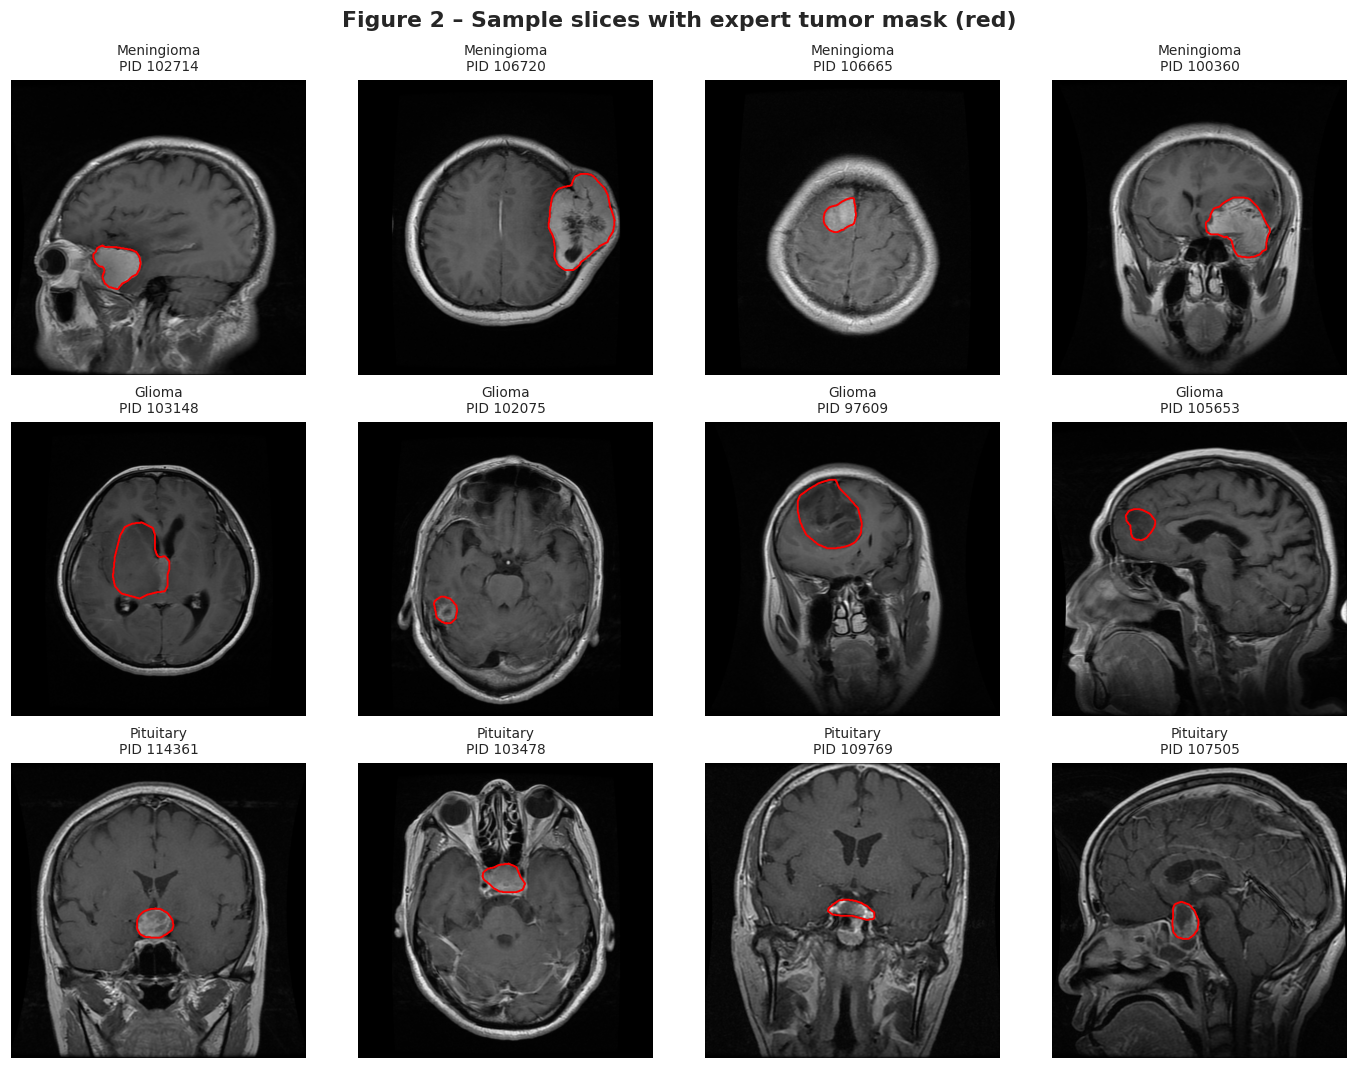

In [ ]:
def show_examples(df, n=4, title="", fname=None, extra=None):
    cls = [c for c in CLASS_ORDER if c in df.tumor_type.values]
    fig, axes = plt.subplots(len(cls), n, figsize=(3.2 * n, 3.3 * len(cls)), squeeze=False)
    for r, c in enumerate(cls):
        sub = df[df.tumor_type == c]
        sub = sub.sample(min(n, len(sub)), random_state=SEED)
        for k in range(n):
            a = axes[r, k]; a.axis("off")
            if k >= len(sub): continue
            row = sub.iloc[k]
            img, mask, _, _ = load_mat(row.file)
            a.imshow(img, cmap="gray")
            a.contour(mask, levels=[0.5], colors=["red"], linewidths=1.2)
            a.set_title(extra(row) if extra else f"{c}\nPID {row.PID}", fontsize=9)
    plt.suptitle(title, fontweight="bold"); plt.tight_layout()
    if fname: savefig(fname)
    else: plt.show()

show_examples(meta, title="Figure 2 – Sample slices with expert tumor mask (red)", fname="fig02_sample_images")

## 5. Patient-level train / test split
Slices from the same patient are highly similar, so the split is done **by patient**. A slice-level split would leak patients into both sets and inflate the accuracy.

**Table 3 – Patient-level train/test split (no patient overlap)**

Slices       Patients      
set          Test Train     Test Train
tumor_type                            
Meningioma    154   551       16    63
Glioma         37   168        4    18
Pituitary     134   488       13    49
Total         325  1207       33   130

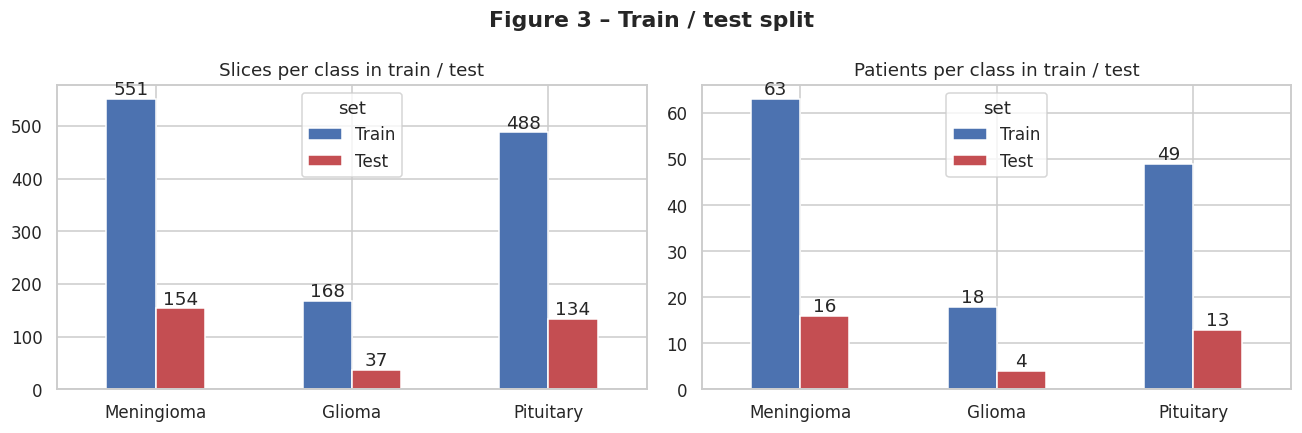

In [ ]:
patients = meta.groupby("PID").agg(label=("y", lambda s: s.mode()[0]), n_slices=("slice_id", "count")).reset_index()
train_pids, test_pids = train_test_split(patients.PID, test_size=TEST_SIZE, stratify=patients.label, random_state=SEED)
meta["set"] = np.where(meta.PID.isin(set(train_pids)), "Train", "Test")
assert not set(meta[meta.set == "Train"].PID) & set(meta[meta.set == "Test"].PID), "Patient leakage!"

split_tab = (meta.groupby(["set", "tumor_type"]).agg(Slices=("slice_id", "count"), Patients=("PID", "nunique"))
             .unstack(0).reindex(CLASS_ORDER))
split_tab.loc["Total"] = split_tab.sum()
display(Markdown("**Table 3 – Patient-level train/test split (no patient overlap)**")); display(split_tab)
savetab(split_tab, "03_train_test_split")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, what in enumerate(["Slices", "Patients"]):
    split_tab.drop("Total")[what][["Train", "Test"]].plot.bar(ax=ax[i], color=["#4C72B0", "#C44E52"], rot=0)
    ax[i].set_title(f"{what} per class in train / test"); ax[i].set_xlabel("")
    for cont in ax[i].containers: ax[i].bar_label(cont)
plt.suptitle("Figure 3 – Train / test split", fontweight="bold"); plt.tight_layout()
savefig("fig03_train_test_split")

## 6. Radiomics feature extraction (PyRadiomics)
**Pre-processing inside PyRadiomics:** z-score intensity normalization (scale 100) → fixed bin-width discretization → 2-D feature calculation on the tumor mask.

**Feature families:** Shape-2D (geometry), First-order (intensity histogram), GLCM, GLRLM, GLSZM, GLDM, NGTDM (texture). Set `ENABLE_FILTERS = True` to add Wavelet and Laplacian-of-Gaussian features.

In [ ]:
import SimpleITK as sitk
from joblib import Parallel, delayed

RADIOMICS_SETTINGS = dict(binWidth=BIN_WIDTH, normalize=True, normalizeScale=100, voxelArrayShift=300,
                          force2D=True, force2Ddimension=0, label=1, correctMask=True,
                          minimumROIDimensions=2, minimumROISize=20, geometryTolerance=1e-3)
_EXTRACTOR = None

def get_extractor():
    global _EXTRACTOR
    if _EXTRACTOR is None:
        from radiomics import featureextractor
        logging.getLogger("radiomics").setLevel(logging.ERROR)
        ext = featureextractor.RadiomicsFeatureExtractor(**RADIOMICS_SETTINGS)
        ext.disableAllFeatures()
        for fc in ["shape2D", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]:
            ext.enableFeatureClassByName(fc)
        if ENABLE_FILTERS:
            ext.enableImageTypes(Original={}, Wavelet={}, LoG={"sigma": [1.0, 2.0, 3.0]})
        else:
            ext.enableImageTypes(Original={})
        _EXTRACTOR = ext
    return _EXTRACTOR

def harmonize(img, mask):
    if HARMONIZE_SIZE and img.shape[0] < HARMONIZE_SIZE:
        f = HARMONIZE_SIZE / img.shape[0]
        from scipy.ndimage import zoom
        img = zoom(img, f, order=1)
        mask = (zoom(mask.astype(np.float32), f, order=0) > 0.5).astype(np.uint8)
    return img, mask

# ---------- Fallback extractor (only used if PyRadiomics is unavailable) ----------
def fallback_features(img, mask):
    from skimage.feature import graycomatrix, graycoprops
    from skimage.measure import regionprops, label as cc_label
    out = {}
    roi = img[mask > 0]
    z = (img - img.mean()) / (img.std() + 1e-8) * 100
    v = z[mask > 0]
    hist, _ = np.histogram(v, bins=np.arange(v.min(), v.max() + BIN_WIDTH, BIN_WIDTH)); p = hist / hist.sum()
    p = p[p > 0]
    fo = dict(Mean=v.mean(), Median=np.median(v), Minimum=v.min(), Maximum=v.max(), Range=np.ptp(v),
              StandardDeviation=v.std(), Variance=v.var(), Skewness=stats.skew(v), Kurtosis=stats.kurtosis(v, fisher=False),
              Energy=np.sum((v + 300) ** 2), RootMeanSquared=np.sqrt(np.mean((v + 300) ** 2)),
              **{"10Percentile": np.percentile(v, 10), "90Percentile": np.percentile(v, 90)},
              InterquartileRange=np.subtract(*np.percentile(v, [75, 25])), MeanAbsoluteDeviation=np.mean(np.abs(v - v.mean())),
              Entropy=-np.sum(p * np.log2(p)), Uniformity=np.sum(p ** 2))
    out.update({f"original_firstorder_{k}": float(val) for k, val in fo.items()})
    rp = max(regionprops(cc_label(mask)), key=lambda r: r.area)
    per = rp.perimeter if rp.perimeter > 0 else 1
    sh = dict(PixelSurface=rp.area, Perimeter=per, PerimeterSurfaceRatio=per / rp.area,
              Sphericity=2 * np.sqrt(np.pi * rp.area) / per, MajorAxisLength=rp.axis_major_length,
              MinorAxisLength=rp.axis_minor_length, Elongation=rp.axis_minor_length / (rp.axis_major_length + 1e-8),
              Eccentricity=rp.eccentricity, Solidity=rp.solidity, Extent=rp.extent)
    out.update({f"original_shape2D_{k}": float(val) for k, val in sh.items()})
    r0, c0, r1, c1 = rp.bbox
    crop = z[r0:r1, c0:c1].copy(); m = mask[r0:r1, c0:c1] > 0
    q = np.clip(((crop - v.min()) / BIN_WIDTH).astype(int) + 1, 1, 255); q[~m] = 0
    lv = int(q.max()) + 1
    glcm = graycomatrix(q.astype(np.uint8), distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=lv, symmetric=True)
    glcm = glcm[1:, 1:].astype(float); glcm /= glcm.sum(axis=(0, 1), keepdims=True) + 1e-12
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]:
        out[f"original_glcm_{prop}"] = float(np.nanmean(graycoprops(glcm, prop)))
    pg = glcm.mean(axis=(2, 3)); pg = pg[pg > 0]
    out["original_glcm_JointEntropy"] = float(-np.sum(pg * np.log2(pg)))
    return out

def extract_one(row):
    img, mask, _, _ = load_mat(row["file"])
    img, mask = harmonize(img, mask)
    try:
        if USE_PYRADIOMICS:
            im = sitk.GetImageFromArray(img[np.newaxis].astype(np.float32))
            ms = sitk.GetImageFromArray(mask[np.newaxis].astype(np.uint8))
            res = get_extractor().execute(im, ms)
            feats = {k: float(np.real(v)) for k, v in res.items() if not k.startswith("diagnostics")}
        else:
            feats = fallback_features(img, mask)
    except Exception as e:
        print("Failed:", row["slice_id"], e); feats = {}
    feats["slice_id"] = row["slice_id"]
    return feats

FEAT_CACHE = os.path.join(RESULTS_DIR, f"radiomics_features_{'filters' if ENABLE_FILTERS else 'original'}.csv")
if os.path.exists(FEAT_CACHE) and set(pd.read_csv(FEAT_CACHE, usecols=["slice_id"]).slice_id.astype(str)) >= set(meta.slice_id):
    feat_df = pd.read_csv(FEAT_CACHE, dtype={"slice_id": str})
    print("Loaded cached features:", FEAT_CACHE); extraction_time = np.nan
else:
    t0 = time.time()
    feats = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(extract_one)(r) for r in meta[["file", "slice_id"]].to_dict("records"))
    extraction_time = time.time() - t0
    feat_df = pd.DataFrame(feats)
    feat_df.to_csv(FEAT_CACHE, index=False)
    print(f"Extraction finished in {extraction_time/60:.1f} min -> saved to {FEAT_CACHE}")

feat_df["slice_id"] = feat_df["slice_id"].astype(str)
data = meta.merge(feat_df, on="slice_id", how="inner")
FEATURES = [c for c in feat_df.columns if c != "slice_id"]
data = data.dropna(subset=FEATURES, how="all").reset_index(drop=True)
print(f"Feature matrix: {len(data)} slices x {len(FEATURES)} radiomic features")

Loaded cached features: /content/drive/MyDrive/radiomics_results/radiomics_features_original.csv
Feature matrix: 1532 slices x 102 radiomic features


## 6b. Extra features: peritumoral ring, tumor location and deep features
* **Peritumoral ring** – the same radiomic texture/intensity features computed on a ring of tissue just outside the tumor border. Meningiomas, gliomas and pituitary tumors differ in how they meet the surrounding tissue (Cheng et al., *PLoS ONE* 2015, used tumor-region augmentation for this reason).
* **Location** – normalized tumor centroid, distance to the image center and to the edge of the head, tumor/head area ratio.
* **Deep features** – a ResNet-50 pretrained on ImageNet (no training needed) turns the tumor crop into 2,048 numbers that describe its visual pattern. Combining these with hand-crafted radiomics is called *hybrid radiomics*.

All three are computed per slice, cached to Drive and simply appended to the feature table; the rest of the notebook is unchanged.

In [ ]:
from scipy import ndimage as ndi
from skimage.morphology import disk
from skimage.filters import threshold_otsu

def head_mask(img):
    m = img > threshold_otsu(img) * 0.5
    m = ndi.binary_fill_holes(ndi.binary_closing(m, iterations=3))
    lab, n = ndi.label(m)
    return (lab == (np.bincount(lab.ravel())[1:].argmax() + 1)) if n else m

_PERI_EXT = None
def get_peri_extractor():
    global _PERI_EXT
    if _PERI_EXT is None:
        from radiomics import featureextractor
        logging.getLogger("radiomics").setLevel(logging.ERROR)
        e = featureextractor.RadiomicsFeatureExtractor(**RADIOMICS_SETTINGS)
        e.disableAllFeatures()
        for fc in ["firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]:
            e.enableFeatureClassByName(fc)
        e.enableImageTypes(Original={})
        _PERI_EXT = e
    return _PERI_EXT

def extra_one(row):
    img, mask, _, _ = load_mat(row["file"])
    img, mask = harmonize(img, mask)
    out = {"slice_id": row["slice_id"]}
    head = head_mask(img) | (mask > 0)
    if ADD_LOCATION:
        H, W = mask.shape
        cy, cx = ndi.center_of_mass(mask)
        hy, hx = ndi.center_of_mass(head)
        dist_edge = ndi.distance_transform_edt(head)
        out.update({
            "context_location_CentroidRow": cy / H, "context_location_CentroidCol": cx / W,
            "context_location_DistToImageCenter": np.hypot(cy / H - 0.5, cx / W - 0.5),
            "context_location_DistToHeadCenter": np.hypot((cy - hy) / H, (cx - hx) / W),
            "context_location_DistToHeadEdge": dist_edge[int(round(cy)), int(round(cx))] / (dist_edge.max() + 1e-8),
            "context_location_MinDistToHeadEdge": dist_edge[mask > 0].min() / (dist_edge.max() + 1e-8),
            "context_location_TumorHeadAreaRatio": mask.sum() / (head.sum() + 1e-8)})
    if ADD_PERITUMORAL:
        ring = (ndi.binary_dilation(mask > 0, structure=disk(PERI_RADIUS)) & ~(mask > 0) & head).astype(np.uint8)
        try:
            if USE_PYRADIOMICS and ring.sum() >= 30:
                res = get_peri_extractor().execute(sitk.GetImageFromArray(img[np.newaxis].astype(np.float32)),
                                                   sitk.GetImageFromArray(ring[np.newaxis]))
                out.update({"peritumoral_" + k.split("_", 1)[1]: float(np.real(v)) for k, v in res.items()
                            if not k.startswith("diagnostics")})
            elif ring.sum() >= 30:
                out.update({"peritumoral_" + k.split("_", 1)[1]: v for k, v in fallback_features(img, ring).items()
                            if "_shape2D_" not in k})
        except Exception as e:
            print("Peritumoral failed:", row["slice_id"], e)
    return out

EXTRA_CACHE = os.path.join(RESULTS_DIR, f"extra_features_r{PERI_RADIUS}_{int(ADD_PERITUMORAL)}{int(ADD_LOCATION)}.csv")
extra_df = None
if ADD_PERITUMORAL or ADD_LOCATION:
    if os.path.exists(EXTRA_CACHE) and set(pd.read_csv(EXTRA_CACHE, usecols=["slice_id"]).slice_id.astype(str)) >= set(data.slice_id):
        extra_df = pd.read_csv(EXTRA_CACHE, dtype={"slice_id": str}); print("Loaded cached extra features")
    else:
        t0 = time.time()
        extra_df = pd.DataFrame(Parallel(n_jobs=N_JOBS, verbose=2)(
            delayed(extra_one)(r) for r in data[["file", "slice_id"]].to_dict("records")))
        extra_df.to_csv(EXTRA_CACHE, index=False)
        print(f"Peritumoral/location features: {extra_df.shape[1]-1} in {(time.time()-t0)/60:.1f} min")

Loaded cached extra features


In [ ]:
# ---------- Deep features: ImageNet ResNet-50 on the tumor crop (no fine-tuning, so no risk of over-fitting here) ----------
DEEP_CACHE = os.path.join(RESULTS_DIR, "deep_features_resnet50.csv")
deep_df = None
if ADD_DEEP:
    if os.path.exists(DEEP_CACHE) and set(pd.read_csv(DEEP_CACHE, usecols=["slice_id"]).slice_id.astype(str)) >= set(data.slice_id):
        deep_df = pd.read_csv(DEEP_CACHE, dtype={"slice_id": str}); print("Loaded cached deep features")
    else:
        import torch, torchvision
        from torchvision.models import resnet50, ResNet50_Weights
        device = "cuda" if torch.cuda.is_available() else "cpu"
        if os.environ.get("TEST_RANDOM_WEIGHTS"):          # offline testing only
            net = resnet50(weights=None)
        else:
            net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        net.fc = torch.nn.Identity(); net = net.eval().to(device)
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

        def tumor_crop(img, mask, margin=0.25, size=224):
            rr, cc = np.where(mask > 0)
            r0, r1, c0, c1 = rr.min(), rr.max(), cc.min(), cc.max()
            side = int(max(r1 - r0, c1 - c0) * (1 + 2 * margin)) + 8
            cy, cx = (r0 + r1) // 2, (c0 + c1) // 2
            pad = side
            im = np.pad(img, pad, mode="constant")
            crop = im[cy - side // 2 + pad: cy + side // 2 + pad, cx - side // 2 + pad: cx + side // 2 + pad]
            lo, hi = np.percentile(img, [0.5, 99.5]); crop = np.clip((crop - lo) / (hi - lo + 1e-8), 0, 1)
            t = torch.tensor(crop, dtype=torch.float32)[None, None]
            return torch.nn.functional.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)[0]

        t0 = time.time(); feats, ids, batch, bids = [], [], [], []
        def flush():
            x = torch.stack(batch).repeat(1, 3, 1, 1).to(device)
            with torch.no_grad():
                f = net((x - mean) / std).cpu().numpy()
            feats.append(f); ids.extend(bids); batch.clear(); bids.clear()
        for r in data[["file", "slice_id"]].to_dict("records"):
            img, mask, _, _ = load_mat(r["file"])
            batch.append(tumor_crop(img, mask)); bids.append(r["slice_id"])
            if len(batch) == 32: flush()
        if batch: flush()
        F = np.concatenate(feats)
        deep_df = pd.DataFrame(F, columns=[f"deep_resnet50_{i:04d}" for i in range(F.shape[1])]); deep_df.insert(0, "slice_id", ids)
        deep_df.to_csv(DEEP_CACHE, index=False)
        print(f"Deep features: {F.shape[1]} per slice in {(time.time()-t0)/60:.1f} min on {device}")

# ---------- merge everything into the feature table ----------
N_RADIOMIC = len(FEATURES)
for extra in [extra_df, deep_df]:
    if extra is not None:
        extra["slice_id"] = extra["slice_id"].astype(str)
        new_cols = [c for c in extra.columns if c != "slice_id"]
        data = data.merge(extra, on="slice_id", how="left")
        FEATURES = FEATURES + new_cols
print(f"Feature matrix: {len(data)} slices x {len(FEATURES)} features "
      f"({N_RADIOMIC} tumor radiomics + {len(FEATURES) - N_RADIOMIC} extra)")

Loaded cached deep features
Feature matrix: 1532 slices x 2250 features (102 tumor radiomics + 2148 extra)


**Table 4 – Extracted features per family**

,Number of features
Feature family,
deep (ResNet-50),2048
peritumoral,93
glcm,24
firstorder,18
glszm,16
glrlm,16
gldm,14
shape2D,9
location,7


**Table 5 – Feature extraction summary**

,Item,Value
0,Slices processed,1532
1,Features per slice,2250
2,Image types,"context, deep, original, peritumoral"
3,Bin width,10
4,Normalization,z-score x100
5,Extraction time (min),cached
6,Extractor,PyRadiomics


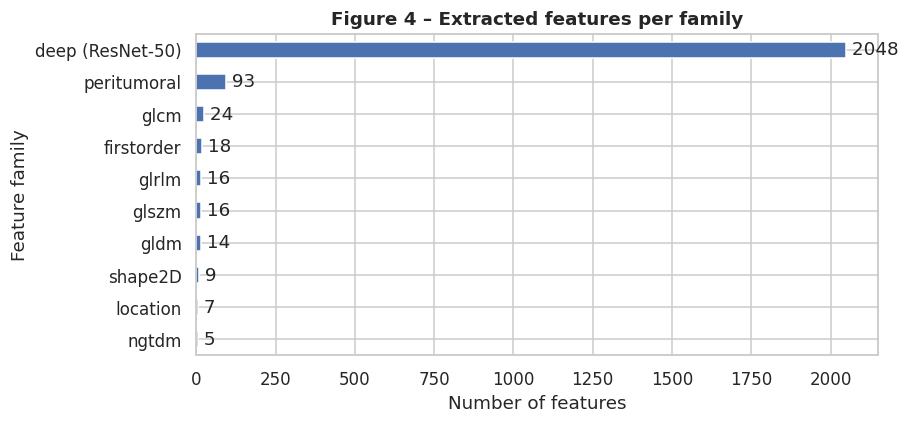

**Table 6 – Extracted feature values (first 5 slices, first 12 features)**

,slice_id,tumor_type,PID,original_shape2D_Elongation,original_shape2D_MajorAxisLength,original_shape2D_MaximumDiameter,original_shape2D_MeshSurface,original_shape2D_MinorAxisLength,original_shape2D_Perimeter,original_shape2D_PerimeterSurfaceRatio,original_shape2D_PixelSurface,original_shape2D_Sphericity,original_firstorder_10Percentile,original_firstorder_90Percentile,original_firstorder_Energy
0,1,Meningioma,100360,0.432,120.219,114.935,4568.5,51.894,312.049,0.068,4569.0,0.768,115.949,231.814,1.039645e+09
1,2,Meningioma,100360,0.860,113.803,121.264,8629.5,97.902,372.676,0.043,8630.0,0.884,91.037,217.949,1.838381e+09
2,3,Meningioma,100360,0.893,124.002,128.098,10510.5,110.687,416.434,0.040,10511.0,0.873,108.649,210.404,2.259413e+09
3,4,Meningioma,100360,0.834,119.327,125.240,8896.5,99.464,406.635,0.046,8897.0,0.822,107.530,226.787,2.005070e+09
4,5,Meningioma,100360,0.792,136.533,148.529,11249.5,108.095,451.019,0.040,11250.0,0.834,-7.772,236.625,1.982865e+09


**Table 7 – Descriptive statistics of all features (first 25 shown; full table saved)**

,mean,std,min,50%,max
original_shape2D_Elongation,7.590000e-01,1.391000e-01,2.644000e-01,7.790000e-01,9.883000e-01
original_shape2D_MajorAxisLength,7.737060e+01,3.371200e+01,2.101090e+01,6.992870e+01,1.952556e+02
original_shape2D_MaximumDiameter,7.958510e+01,3.464590e+01,2.158700e+01,7.254650e+01,2.055480e+02
original_shape2D_MeshSurface,3.928367e+03,3.366417e+03,2.545000e+02,2.800500e+03,2.107950e+04
original_shape2D_MinorAxisLength,5.754990e+01,2.451430e+01,1.276760e+01,5.306270e+01,1.517989e+02
original_shape2D_Perimeter,2.354462e+02,1.046245e+02,6.311270e+01,2.137315e+02,6.976539e+02
original_shape2D_PerimeterSurfaceRatio,8.240000e-02,3.570000e-02,2.810000e-02,7.600000e-02,3.208000e-01
original_shape2D_PixelSurface,3.928871e+03,3.366416e+03,2.550000e+02,2.801000e+03,2.108000e+04
original_shape2D_Sphericity,8.812000e-01,6.170000e-02,5.136000e-01,9.017000e-01,9.512000e-01
original_firstorder_10Percentile,7.465120e+01,4.838970e+01,-8.711880e+01,7.714380e+01,2.615780e+02


In [ ]:
def family(f):
    parts = f.split("_")
    if parts[0] in ("peritumoral", "deep", "context"):
        return {"peritumoral": "peritumoral", "deep": "deep (ResNet-50)", "context": "location"}[parts[0]]
    return parts[1] if len(parts) > 2 else "other"
def image_type(f):
    return f.split("_")[0]

fam = pd.Series([family(f) for f in FEATURES]).value_counts().rename_axis("Feature family").rename("Number of features")
display(Markdown("**Table 4 – Extracted features per family**")); display(fam.to_frame())
savetab(fam.to_frame(), "04_feature_families")

ext_tab = pd.DataFrame({"Item": ["Slices processed", "Features per slice", "Image types", "Bin width",
                                 "Normalization", "Extraction time (min)", "Extractor"],
                        "Value": [len(data), len(FEATURES), ", ".join(sorted({image_type(f) for f in FEATURES})), BIN_WIDTH,
                                  "z-score x100", "cached" if np.isnan(extraction_time) else round(extraction_time / 60, 2),
                                  "PyRadiomics" if USE_PYRADIOMICS else "Fallback (numpy/scikit-image)"]})
display(Markdown("**Table 5 – Feature extraction summary**")); display(ext_tab)
savetab(ext_tab, "05_extraction_summary", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
fam.sort_values().plot.barh(ax=ax, color="#4C72B0")
for i, v in enumerate(fam.sort_values().values): ax.text(v, i, f" {v}", va="center")
ax.set_xlabel("Number of features"); ax.set_title("Figure 4 – Extracted features per family", fontweight="bold")
savefig("fig04_feature_families")

display(Markdown("**Table 6 – Extracted feature values (first 5 slices, first 12 features)**"))
display(data[["slice_id", "tumor_type", "PID"] + FEATURES[:12]].head().round(3))
desc = data[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
display(Markdown("**Table 7 – Descriptive statistics of all features (first 25 shown; full table saved)**"))
display(desc.head(25).round(4))
savetab(desc, "07_feature_descriptive_stats")
data[["slice_id", "PID", "tumor_type", "set"] + FEATURES].to_csv(os.path.join(TAB_DIR, "06_all_radiomic_features.csv"), index=False)

## 7. Feature analysis on the training set

Train: (1207, 2250) | Test: (325, 2250)


**Table 8 – Kruskal–Wallis test (top 15)** — 1236 of 2250 features differ significantly between classes (Bonferroni p < 0.05)

,Feature,Family,H statistic,p-value,p (Bonferroni)
0,peritumoral_glszm_LargeAreaHighGrayLevelEmphasis,peritumoral,635.3,1.13e-138,2.53e-135
1,context_location_MinDistToHeadEdge,location,618.9,4.02e-135,9.04e-132
2,peritumoral_glrlm_RunPercentage,peritumoral,578.7,2.21e-126,4.96e-123
3,peritumoral_glrlm_ShortRunEmphasis,peritumoral,577.4,4.24e-126,9.55e-123
4,peritumoral_glrlm_RunLengthNonUniformityNormalized,peritumoral,576.8,5.55e-126,1.25e-122
5,peritumoral_gldm_LargeDependenceEmphasis,peritumoral,574.1,2.17e-125,4.89e-122
6,peritumoral_glcm_Id,peritumoral,567.8,5.11e-124,1.15e-120
7,peritumoral_glrlm_LongRunEmphasis,peritumoral,567.3,6.41e-124,1.44e-120
8,peritumoral_glcm_Idm,peritumoral,565.5,1.57e-123,3.54e-120
9,context_location_DistToHeadCenter,location,565.2,1.89e-123,4.25e-120


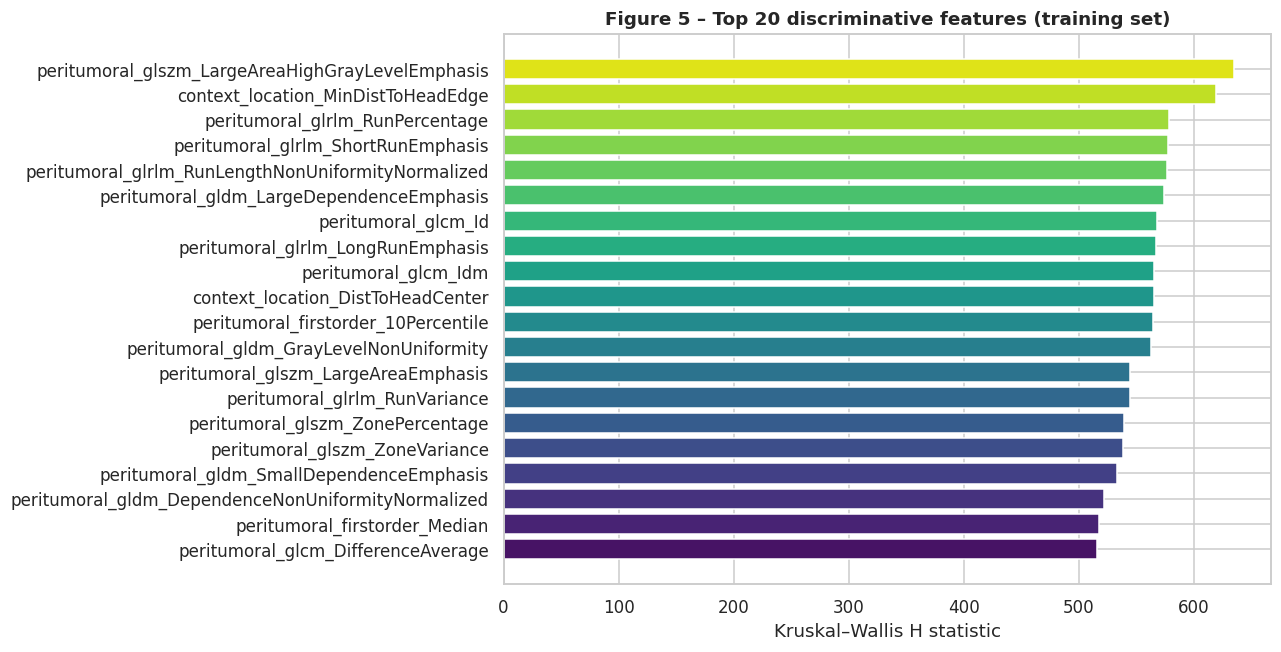

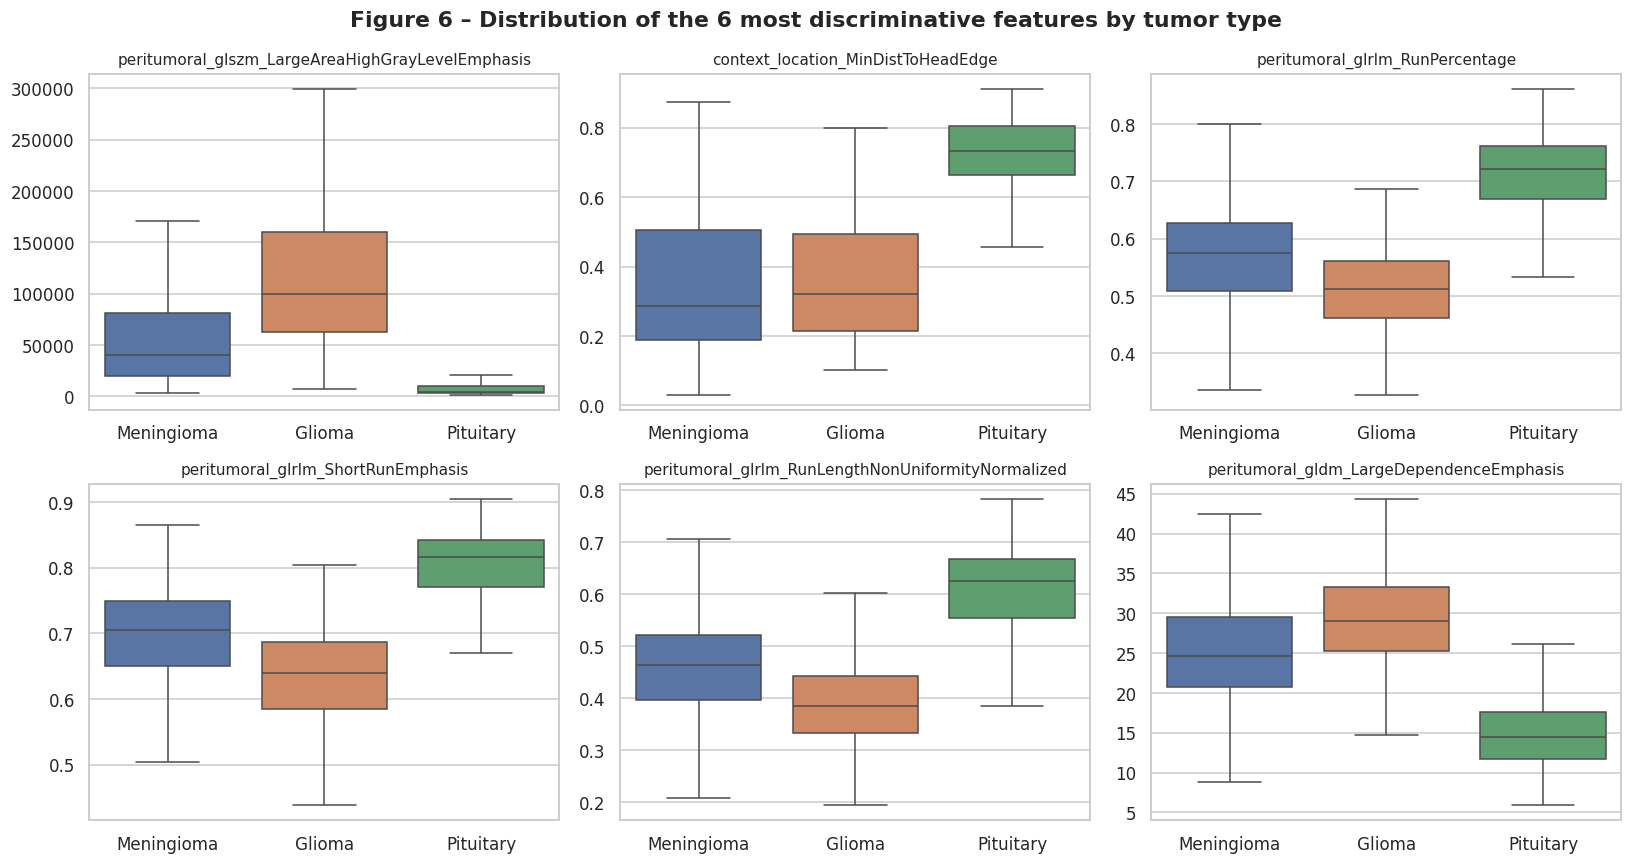

In [ ]:
train = data[data.set == "Train"].reset_index(drop=True)
test  = data[data.set == "Test"].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES].values, train.y.values, train.PID.values
X_test,  y_test,  g_test  = test[FEATURES].values,  test.y.values,  test.PID.values
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Kruskal-Wallis test of every feature across the 3 tumor classes (training set only)
kw = []
for f in FEATURES:
    groups = [train.loc[train.y == k, f].dropna() for k in range(3)]
    try:
        H, p = stats.kruskal(*groups)
    except ValueError:
        H, p = 0.0, 1.0
    kw.append((f, family(f), H, p))
kw = pd.DataFrame(kw, columns=["Feature", "Family", "H statistic", "p-value"]).sort_values("H statistic", ascending=False)
m = len(kw); kw["p (Bonferroni)"] = np.minimum(kw["p-value"] * m, 1.0)
n_sig = (kw["p (Bonferroni)"] < 0.05).sum()
display(Markdown(f"**Table 8 – Kruskal–Wallis test (top 15)** — {n_sig} of {m} features differ significantly between classes (Bonferroni p < 0.05)"))
display(kw.head(15).reset_index(drop=True).style.format({"H statistic": "{:.1f}", "p-value": "{:.2e}", "p (Bonferroni)": "{:.2e}"}))
savetab(kw, "08_kruskal_wallis", index=False)

top = kw.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.Feature.str.replace("original_", ""), top["H statistic"], color=sns.color_palette("viridis", 20))
ax.set_xlabel("Kruskal–Wallis H statistic"); ax.set_title("Figure 5 – Top 20 discriminative features (training set)", fontweight="bold")
savefig("fig05_top_features_kruskal")

top6 = kw.Feature.head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, f in zip(axes.flat, top6):
    sns.boxplot(data=train, x="tumor_type", y=f, order=CLASS_ORDER, palette=CLASS_COLORS, ax=a, showfliers=False)
    a.set_title(f.replace("original_", ""), fontsize=10); a.set_xlabel(""); a.set_ylabel("")
plt.suptitle("Figure 6 – Distribution of the 6 most discriminative features by tumor type", fontweight="bold"); plt.tight_layout()
savefig("fig06_feature_boxplots")

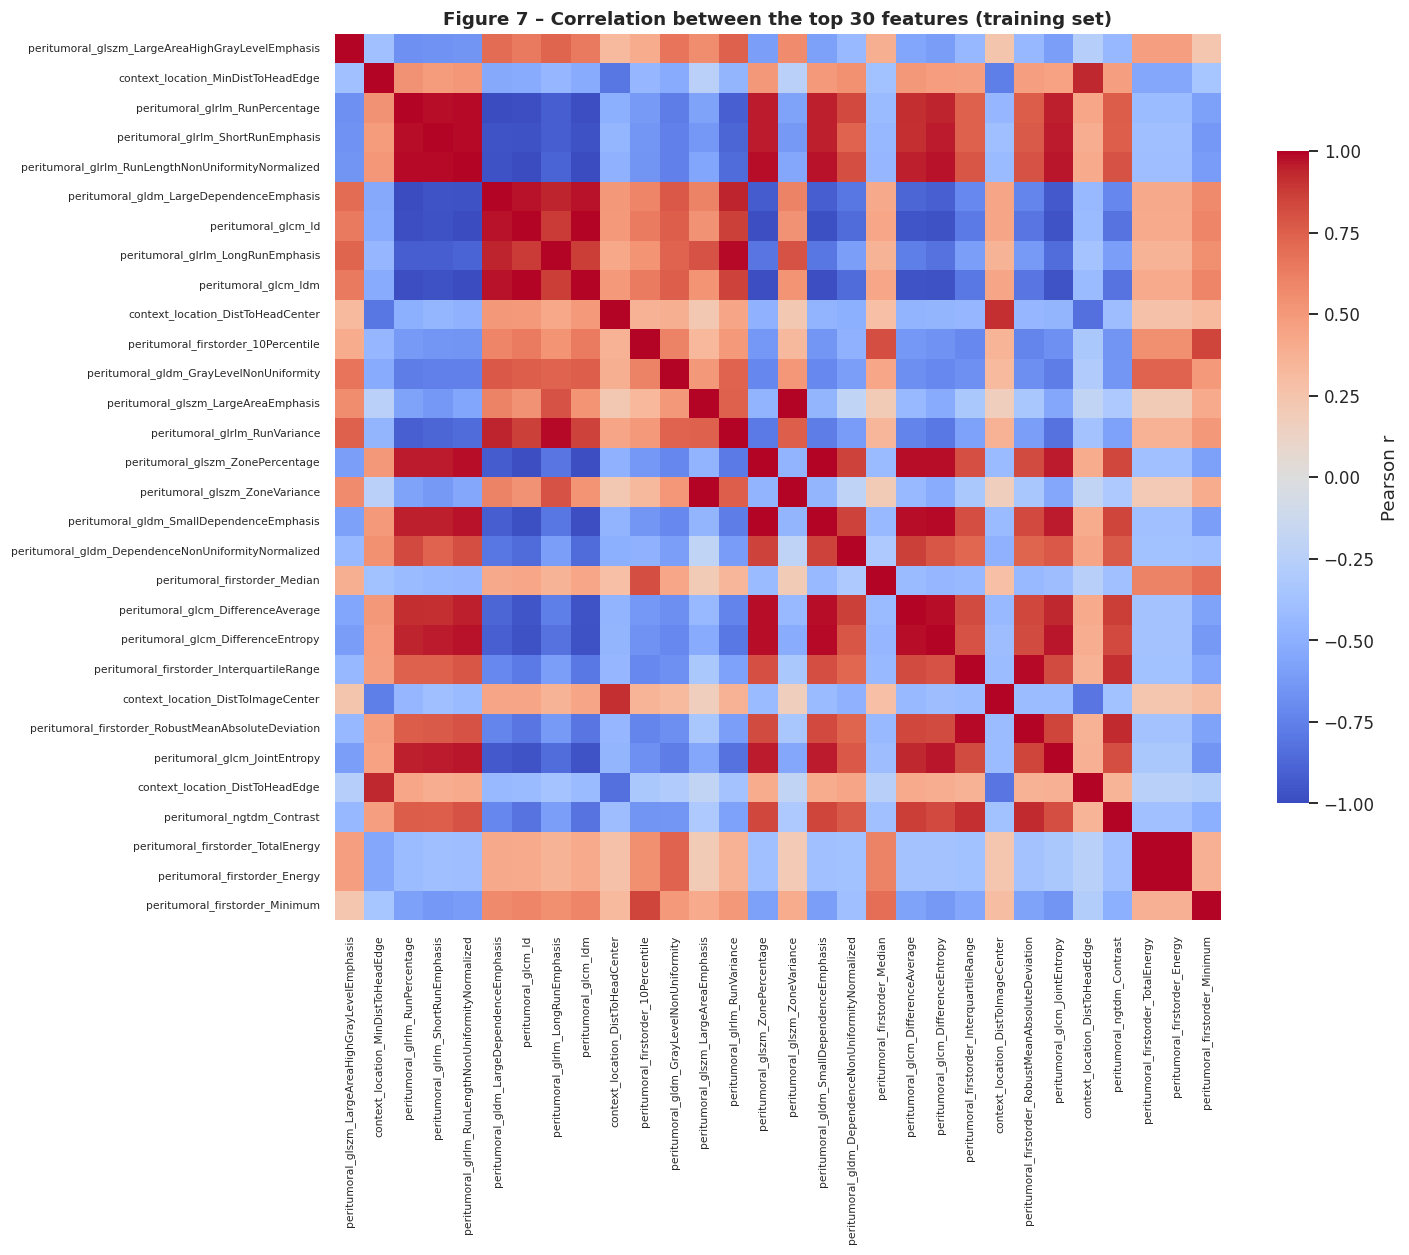

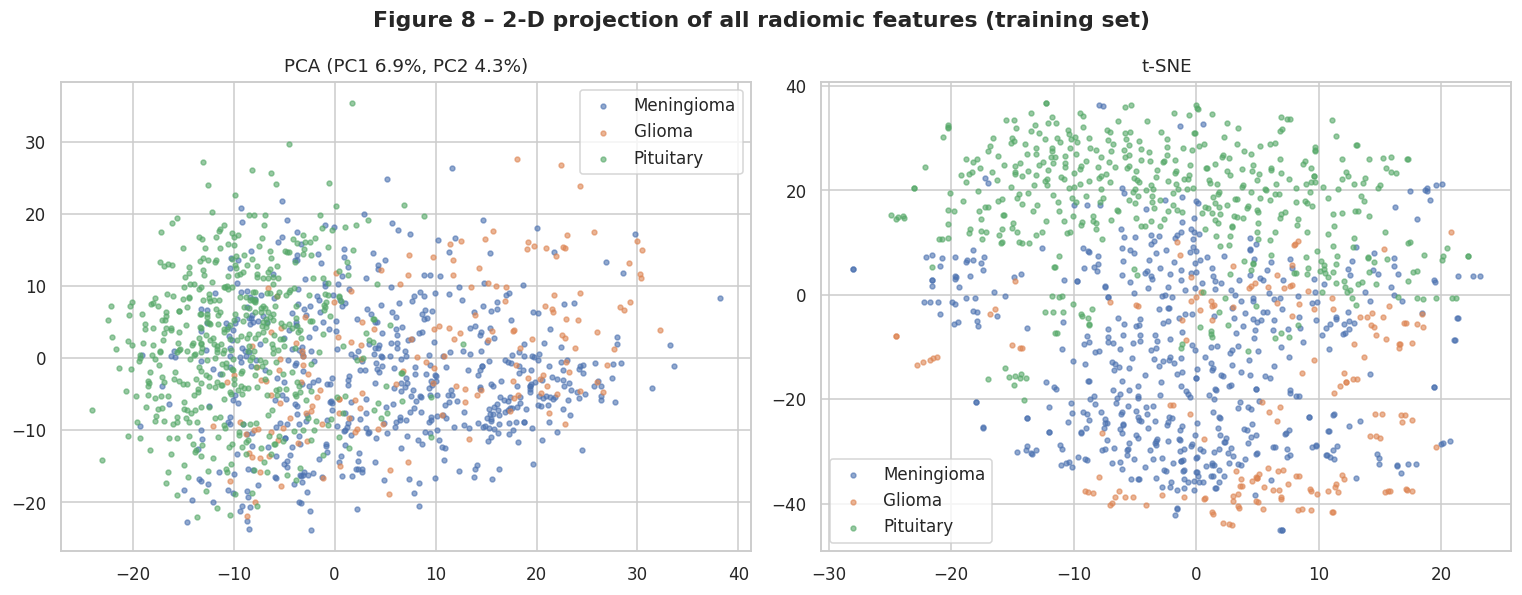

In [ ]:
top30 = kw.Feature.head(30).tolist()
corr = train[top30].corr()
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=[f.replace("original_", "") for f in top30], yticklabels=[f.replace("original_", "") for f in top30],
            cbar_kws={"shrink": 0.7, "label": "Pearson r"})
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.title("Figure 7 – Correlation between the top 30 features (training set)", fontweight="bold")
savefig("fig07_feature_correlation")

Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_train))
pca = PCA(n_components=2, random_state=SEED).fit(Xs); P = pca.transform(Xs)
T = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca").fit_transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for name, k in zip(CLASS_ORDER, range(3)):
    ax[0].scatter(P[y_train == k, 0], P[y_train == k, 1], s=10, alpha=0.6, c=CLASS_COLORS[name], label=name)
    ax[1].scatter(T[y_train == k, 0], T[y_train == k, 1], s=10, alpha=0.6, c=CLASS_COLORS[name], label=name)
ax[0].set_title(f"PCA (PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%})")
ax[1].set_title("t-SNE"); [a.legend() for a in ax]
plt.suptitle("Figure 8 – 2-D projection of all radiomic features (training set)", fontweight="bold"); plt.tight_layout()
savefig("fig08_pca_tsne")

## 8. Feature selection pipeline
`Median imputation → Variance threshold → Correlation filter (|r| > 0.90) → Standardization → ANOVA-F top-K → Classifier`

All selection steps sit **inside** the sklearn pipeline, so during cross-validation they are re-fitted on each training fold only (no selection bias).

In [ ]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    # Greedily drops the later feature of every pair whose |Pearson r| exceeds the threshold.
    def __init__(self, threshold=0.9):
        self.threshold = threshold
    def fit(self, X, y=None):
        c = np.abs(np.corrcoef(X, rowvar=False)); c = np.nan_to_num(c)
        keep = np.ones(X.shape[1], bool)
        for i in range(X.shape[1]):
            if keep[i]:
                drop = (c[i] > self.threshold) & (np.arange(X.shape[1]) > i)
                keep[drop] = False
        self.support_ = keep
        return self
    def transform(self, X):
        return X[:, self.support_]

class SafeKBest(BaseEstimator, TransformerMixin):
    # ANOVA-F top-k that never asks for more features than are available.
    def __init__(self, k=30):
        self.k = k
    def fit(self, X, y):
        F, p = f_classif(X, y); F = np.nan_to_num(F)
        k = min(self.k, X.shape[1])
        self.scores_, self.pvalues_ = F, p
        self.support_ = np.zeros(X.shape[1], bool); self.support_[np.argsort(F)[::-1][:k]] = True
        return self
    def transform(self, X):
        return X[:, self.support_]

def make_pipeline(clf):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("var", VarianceThreshold(1e-8)),
                     ("corr", CorrelationFilter(CORR_THRESHOLD)),
                     ("scale", StandardScaler()),
                     ("select", SafeKBest(K_FEATURES)),
                     ("clf", clf)])

|r|>0.90  K=  20  CV acc=0.8699  F1=0.8334
|r|>0.90  K=  30  CV acc=0.8965  F1=0.8751
|r|>0.90  K=  50  CV acc=0.8996  F1=0.8847
|r|>0.90  K=  80  CV acc=0.9099  F1=0.8934
|r|>0.90  K= 100  CV acc=0.9045  F1=0.8866
|r|>0.90  K= 150  CV acc=0.8958  F1=0.8806
|r|>0.90  K= 200  CV acc=0.9030  F1=0.8851
|r|>0.95  K=  20  CV acc=0.8390  F1=0.7964
|r|>0.95  K=  30  CV acc=0.8798  F1=0.8546
|r|>0.95  K=  50  CV acc=0.9002  F1=0.8872
|r|>0.95  K=  80  CV acc=0.9040  F1=0.8857
|r|>0.95  K= 100  CV acc=0.9061  F1=0.8906
|r|>0.95  K= 150  CV acc=0.9016  F1=0.8856
|r|>0.95  K= 200  CV acc=0.9067  F1=0.8908
|r|>0.99  K=  20  CV acc=0.8308  F1=0.7912
|r|>0.99  K=  30  CV acc=0.8600  F1=0.8365
|r|>0.99  K=  50  CV acc=0.8900  F1=0.8720
|r|>0.99  K=  80  CV acc=0.9049  F1=0.8888
|r|>0.99  K= 100  CV acc=0.9014  F1=0.8825
|r|>0.99  K= 150  CV acc=0.9109  F1=0.8997
|r|>0.99  K= 200  CV acc=0.9094  F1=0.8960


**Table 8b – Tuning of K and the correlation threshold (5-fold patient-grouped CV, SVM, training set only)**

,Corr threshold,Features after corr filter,K,CV accuracy,CV acc SD,CV macro-F1
0,0.990000,2214,150,0.9109,0.0333,0.8997
1,0.990000,2214,200,0.9094,0.0319,0.8960
2,0.900000,2148,80,0.9099,0.0354,0.8934
3,0.950000,2174,200,0.9067,0.0366,0.8908
4,0.950000,2174,100,0.9061,0.0308,0.8906
5,0.990000,2214,80,0.9049,0.0239,0.8888
6,0.950000,2174,50,0.9002,0.0373,0.8872
7,0.900000,2148,100,0.9045,0.0392,0.8866
8,0.950000,2174,80,0.9040,0.0319,0.8857
9,0.950000,2174,150,0.9016,0.0317,0.8856


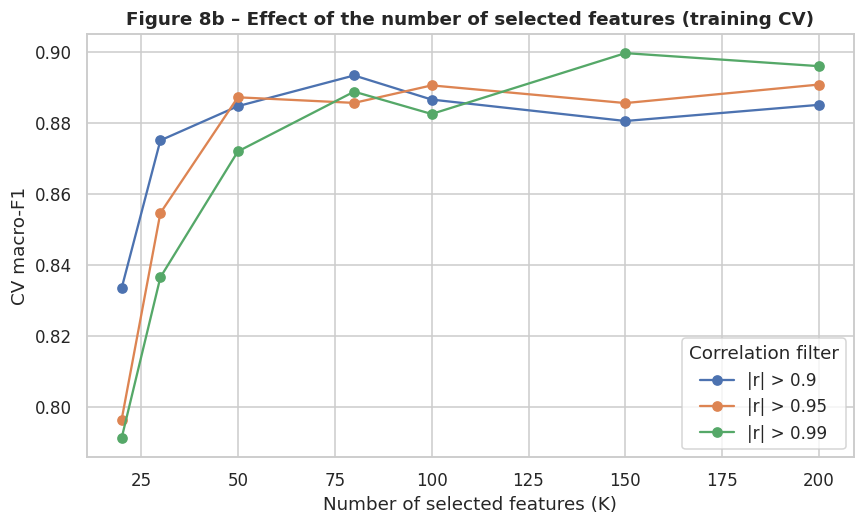

Using K_FEATURES = 150, CORR_THRESHOLD = 0.99


In [ ]:
# ===== Tune K (number of selected features) and the correlation threshold with patient-grouped CV =====
# Uses ONLY the training set, so the test set stays untouched (no tuning on test data).
if TUNE_SELECTION:
    TUNE_MODEL = SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", random_state=SEED)
    K_GRID   = [20, 30, 50, 80, 100, 150, 200]
    THR_GRID = [0.90, 0.95, 0.99]
    cv_tune  = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    rows = []
    for thr in THR_GRID:
        pre = Pipeline([("impute", SimpleImputer(strategy="median")), ("var", VarianceThreshold(1e-8)),
                        ("corr", CorrelationFilter(thr))]).fit(X_train)
        n_after = int(pre.named_steps["corr"].support_.sum())
        for k in sorted({min(k, n_after) for k in K_GRID}):
            pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("var", VarianceThreshold(1e-8)),
                             ("corr", CorrelationFilter(thr)), ("scale", StandardScaler()),
                             ("select", SafeKBest(k)), ("clf", clone(TUNE_MODEL))])
            r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv_tune,
                               scoring={"acc": "accuracy", "f1": "f1_macro"}, n_jobs=-1)
            rows.append({"Corr threshold": thr, "Features after corr filter": n_after, "K": k,
                         "CV accuracy": r["test_acc"].mean(), "CV acc SD": r["test_acc"].std(), "CV macro-F1": r["test_f1"].mean()})
            print(f"|r|>{thr:.2f}  K={k:4d}  CV acc={r['test_acc'].mean():.4f}  F1={r['test_f1'].mean():.4f}")
    tune = pd.DataFrame(rows).sort_values(["CV macro-F1", "K"], ascending=[False, True]).reset_index(drop=True)
    display(Markdown("**Table 8b – Tuning of K and the correlation threshold (5-fold patient-grouped CV, SVM, training set only)**"))
    display(tune.style.format({"CV accuracy": "{:.4f}", "CV acc SD": "{:.4f}", "CV macro-F1": "{:.4f}"})
            .highlight_max(subset=["CV macro-F1"], color="#c7e9c0"))
    savetab(tune, "08b_feature_selection_tuning", index=False)

    fig, ax = plt.subplots(figsize=(9, 5))
    for thr, g in tune.groupby("Corr threshold"):
        g = g.sort_values("K"); ax.plot(g.K, g["CV macro-F1"], "o-", label=f"|r| > {thr}")
    ax.set_xlabel("Number of selected features (K)"); ax.set_ylabel("CV macro-F1"); ax.legend(title="Correlation filter")
    ax.set_title("Figure 8b – Effect of the number of selected features (training CV)", fontweight="bold")
    savefig("fig08b_feature_selection_tuning")

    K_FEATURES, CORR_THRESHOLD = int(tune.loc[0, "K"]), float(tune.loc[0, "Corr threshold"])
print(f"Using K_FEATURES = {K_FEATURES}, CORR_THRESHOLD = {CORR_THRESHOLD}")

**Table 9 – Feature reduction**

,Step,Features
0,Extracted,2250
1,After variance threshold,2250
2,After correlation filter (|r|>0.99),2214
3,Selected (ANOVA-F top 150),150


**Table 10 – Selected radiomic features (fitted on the full training set)**

,Feature,Family,F score,p-value
0,context_location_MinDistToHeadEdge,location,629.0,9.54e-188
1,peritumoral_glcm_Id,peritumoral,522.4,4.57e-164
2,peritumoral_firstorder_10Percentile,peritumoral,511.7,1.49e-161
3,peritumoral_glszm_ZonePercentage,peritumoral,487.2,9.72e-156
4,peritumoral_gldm_LargeDependenceEmphasis,peritumoral,480.9,3.19e-154
5,peritumoral_glrlm_ShortRunEmphasis,peritumoral,469.3,2.00e-151
6,peritumoral_gldm_DependenceNonUniformityNormalized,peritumoral,451.8,4.19e-147
7,peritumoral_glcm_DifferenceEntropy,peritumoral,429.8,1.39e-141
8,peritumoral_firstorder_InterquartileRange,peritumoral,428.8,2.38e-141
9,peritumoral_glcm_DifferenceAverage,peritumoral,428.4,3.15e-141


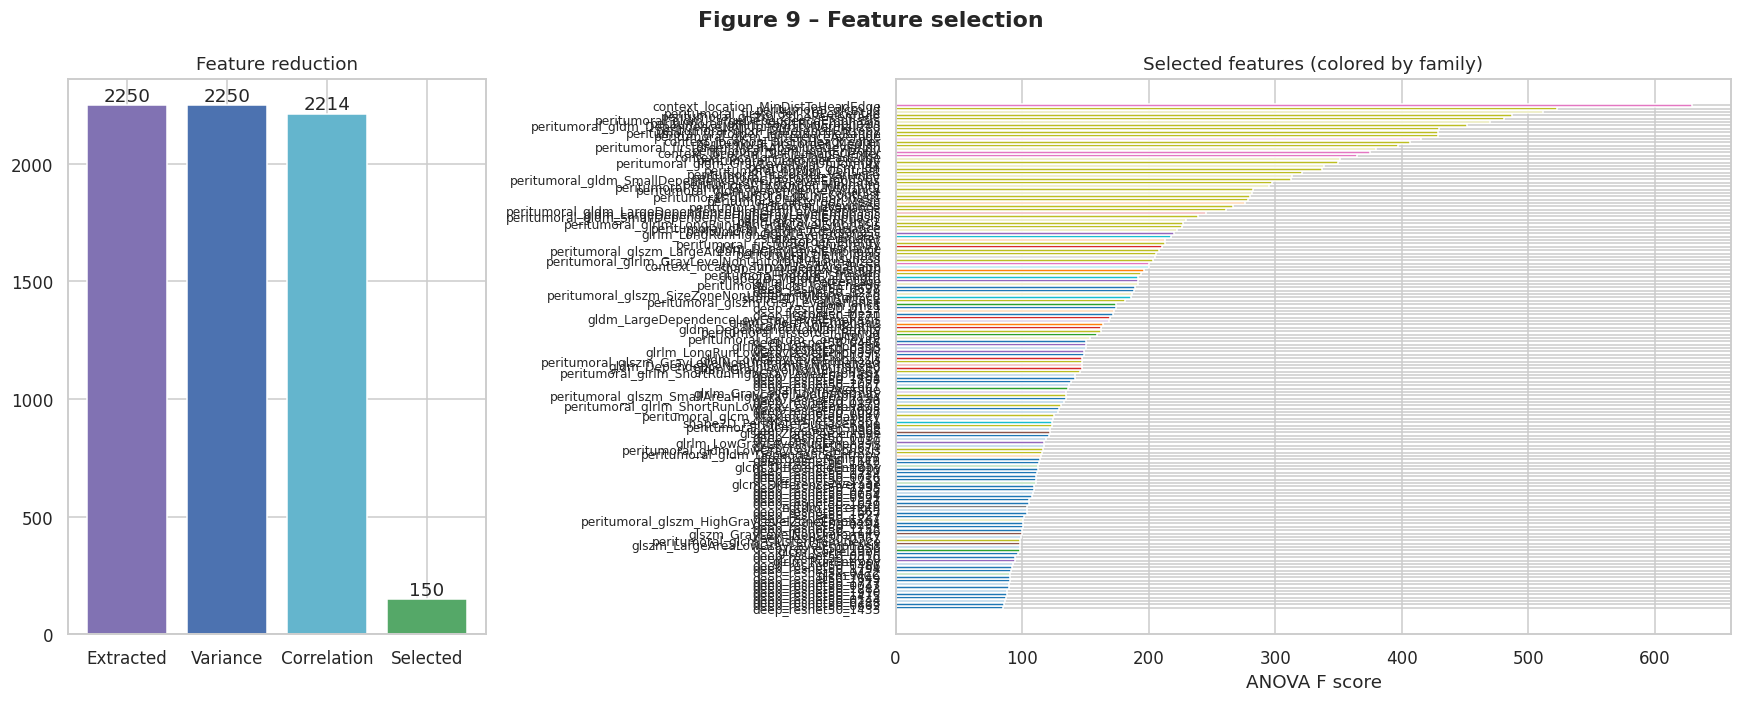

Selected-feature families: {'deep (ResNet-50)': 55, 'peritumoral': 52, 'glrlm': 8, 'glcm': 7, 'gldm': 7, 'firstorder': 6, 'location': 5, 'shape2D': 5, 'glszm': 3, 'ngtdm': 2}


In [ ]:
# Fit the selection steps once on the whole training set to report which features are kept
sel = make_pipeline(LogisticRegression()).steps[:-1]
sel = Pipeline(sel).fit(X_train, y_train)
names = np.array(FEATURES)
after_var = names[sel.named_steps["var"].get_support()]
after_corr = after_var[sel.named_steps["corr"].support_]
kb = sel.named_steps["select"]
selected = after_corr[kb.support_]

funnel = pd.DataFrame({"Step": ["Extracted", "After variance threshold", f"After correlation filter (|r|>{CORR_THRESHOLD})",
                                f"Selected (ANOVA-F top {K_FEATURES})"],
                       "Features": [len(FEATURES), len(after_var), len(after_corr), len(selected)]})
display(Markdown("**Table 9 – Feature reduction**")); display(funnel)
savetab(funnel, "09_feature_reduction", index=False)

sel_tab = pd.DataFrame({"Feature": selected, "Family": [family(f) for f in selected],
                        "F score": kb.scores_[kb.support_], "p-value": kb.pvalues_[kb.support_]}).sort_values("F score", ascending=False)
display(Markdown("**Table 10 – Selected radiomic features (fitted on the full training set)**"))
display(sel_tab.reset_index(drop=True).style.format({"F score": "{:.1f}", "p-value": "{:.2e}"}))
savetab(sel_tab, "10_selected_features", index=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(range(4), funnel.Features, color=["#8172B3", "#4C72B0", "#64B5CD", "#55A868"])
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["Extracted", "Variance", "Correlation", "Selected"])
for i, v in enumerate(funnel.Features): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_title("Feature reduction")
st = sel_tab.iloc[::-1]
ax[1].barh(st.Feature.str.replace("original_", ""), st["F score"],
           color=[sns.color_palette("tab10")[sorted(set(sel_tab.Family)).index(f)] for f in st.Family])
ax[1].set_xlabel("ANOVA F score"); ax[1].set_title("Selected features (colored by family)"); ax[1].tick_params(axis="y", labelsize=8)
plt.suptitle("Figure 9 – Feature selection", fontweight="bold"); plt.tight_layout()
savefig("fig09_feature_selection")
print("Selected-feature families:", sel_tab.Family.value_counts().to_dict())

## 9. Model training with 5-fold patient-grouped cross-validation (training set)
Seven classifiers are compared (six individual models and a soft-voting ensemble). `StratifiedGroupKFold` keeps all slices of a patient in the same fold. Class imbalance is handled with `class_weight="balanced"` (and sample weights for XGBoost).

In [ ]:
MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=5000, C=1.0, class_weight="balanced", random_state=SEED),
    "SVM (RBF)":           SVC(kernel="rbf", C=10, gamma="scale", probability=True, class_weight="balanced", random_state=SEED),
    "KNN":                 KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Random Forest":       RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost":             XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                                         colsample_bytree=0.8, eval_metric="mlogloss", random_state=SEED, n_jobs=-1),
    "MLP":                 MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=2000, early_stopping=True, random_state=SEED),
}
from sklearn.ensemble import VotingClassifier
MODELS["Ensemble (soft voting)"] = VotingClassifier(
    estimators=[("lr", clone(MODELS["Logistic Regression"])), ("svm", clone(MODELS["SVM (RBF)"])),
                ("rf", clone(MODELS["Random Forest"])), ("xgb", clone(MODELS["XGBoost"]))], voting="soft", n_jobs=1)
cw = len(y_train) / (3 * np.bincount(y_train))
def fit_params(name, y):
    return {"clf__sample_weight": cw[y]} if name == "XGBoost" else {}

cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
SCORING = {"Accuracy": "accuracy", "Balanced Acc": "balanced_accuracy", "Precision": "precision_macro",
           "Recall": "recall_macro", "F1": "f1_macro", "AUC": "roc_auc_ovr"}

cv_rows, cv_folds, oof_proba, train_time = [], {}, {}, {}
for name, clf in MODELS.items():
    t0 = time.time()
    res = cross_validate(make_pipeline(clf), X_train, y_train, groups=g_train, cv=cv, scoring=SCORING,
                         return_train_score=True, params=fit_params(name, y_train), n_jobs=1)
    oof_proba[name] = cross_val_predict(make_pipeline(clf), X_train, y_train, groups=g_train, cv=cv,
                                        method="predict_proba", params=fit_params(name, y_train))
    train_time[name] = time.time() - t0
    cv_folds[name] = res
    row = {"Model": name}
    for k in SCORING:
        row[f"CV {k}"] = f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}"
    row["Train-fold Accuracy"] = f"{res['train_Accuracy'].mean():.3f}"
    row["Time (s)"] = round(train_time[name], 1)
    cv_rows.append(row)
    print(f"{name:20s} CV accuracy {res['test_Accuracy'].mean():.3f}  F1 {res['test_F1'].mean():.3f}  ({train_time[name]:.0f}s)")

cv_table = pd.DataFrame(cv_rows).set_index("Model")
display(Markdown(f"**Table 11 – {N_FOLDS}-fold patient-grouped cross-validation results on the training set (mean ± SD)**"))
display(cv_table)
savetab(cv_table, "11_cross_validation")

BEST = max(MODELS, key=lambda n: cv_folds[n]["test_F1"].mean())
display(Markdown(f"### Best model by CV macro-F1: **{BEST}**  (selected on cross-validation, *not* on the test set)"))

Logistic Regression  CV accuracy 0.892  F1 0.874  (11s)
SVM (RBF)            CV accuracy 0.911  F1 0.900  (12s)
KNN                  CV accuracy 0.868  F1 0.820  (8s)
Random Forest        CV accuracy 0.897  F1 0.883  (62s)
XGBoost              CV accuracy 0.919  F1 0.905  (84s)
MLP                  CV accuracy 0.904  F1 0.886  (17s)
Ensemble (soft voting) CV accuracy 0.921  F1 0.913  (144s)


**Table 11 – 5-fold patient-grouped cross-validation results on the training set (mean ± SD)**

,CV Accuracy,CV Balanced Acc,CV Precision,CV Recall,CV F1,CV AUC,Train-fold Accuracy,Time (s)
Model,,,,,,,,
Logistic Regression,0.892 ± 0.030,0.891 ± 0.022,0.864 ± 0.038,0.891 ± 0.022,0.874 ± 0.031,0.976 ± 0.012,0.995,11.2
SVM (RBF),0.911 ± 0.033,0.906 ± 0.028,0.895 ± 0.029,0.906 ± 0.028,0.900 ± 0.028,0.977 ± 0.011,1.000,12.4
KNN,0.868 ± 0.047,0.801 ± 0.066,0.875 ± 0.033,0.801 ± 0.066,0.820 ± 0.059,0.953 ± 0.013,1.000,8.3
Random Forest,0.897 ± 0.062,0.874 ± 0.053,0.898 ± 0.059,0.874 ± 0.053,0.883 ± 0.055,0.975 ± 0.017,1.000,61.7
XGBoost,0.919 ± 0.039,0.907 ± 0.030,0.908 ± 0.049,0.907 ± 0.030,0.905 ± 0.038,0.981 ± 0.011,1.000,84.4
MLP,0.904 ± 0.036,0.883 ± 0.052,0.894 ± 0.043,0.883 ± 0.052,0.886 ± 0.046,0.976 ± 0.017,0.983,16.7
Ensemble (soft voting),0.921 ± 0.038,0.912 ± 0.026,0.917 ± 0.046,0.912 ± 0.026,0.913 ± 0.035,0.983 ± 0.012,1.000,143.8


### Best model by CV macro-F1: **Ensemble (soft voting)**  (selected on cross-validation, *not* on the test set)

**Table 12 – Fold-wise training and validation scores**

Model,Ensemble (soft voting),KNN,Logistic Regression,MLP,Random Forest,SVM (RBF),XGBoost
Fold,,,,,,,
1,0.847,0.780,0.843,0.851,0.776,0.847,0.843
2,0.952,0.866,0.914,0.943,0.943,0.943,0.943
3,0.940,0.911,0.915,0.940,0.936,0.918,0.932
4,0.938,0.877,0.915,0.912,0.931,0.931,0.927
5,0.926,0.906,0.871,0.876,0.901,0.916,0.950


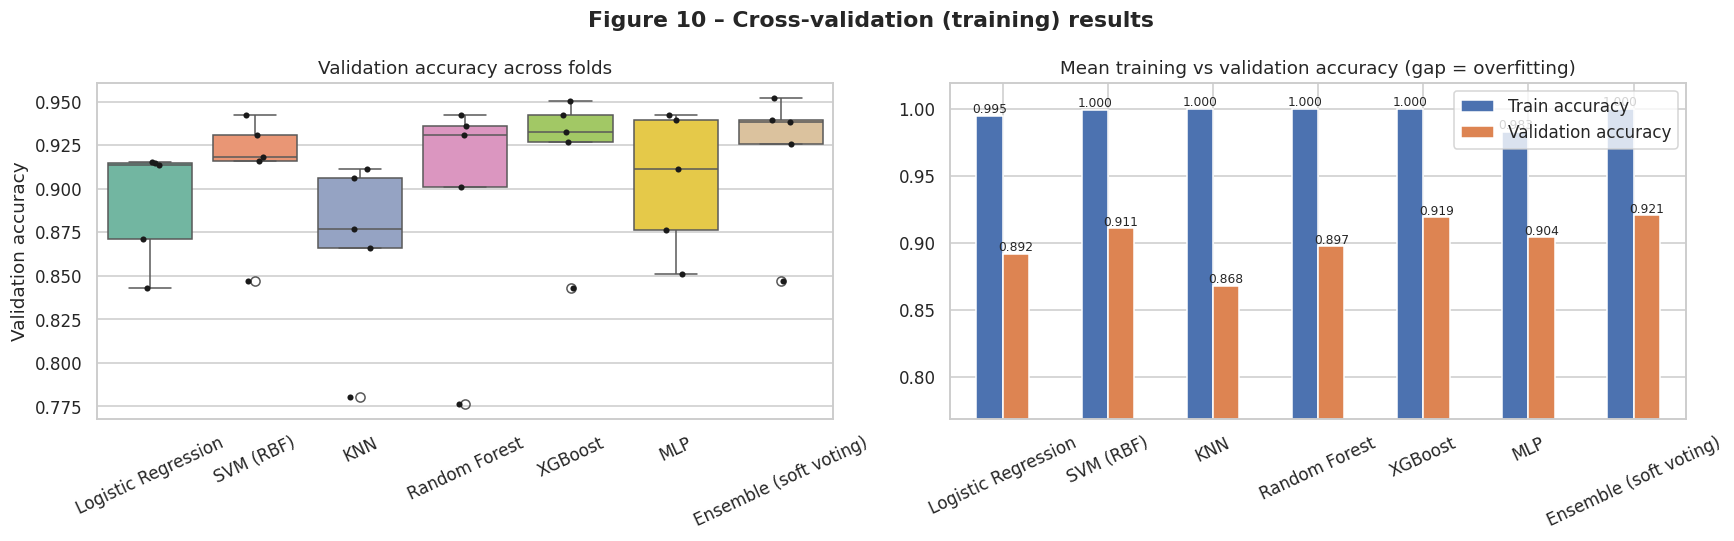

In [ ]:
fold_df = pd.concat([pd.DataFrame({"Model": n, "Fold": np.arange(1, N_FOLDS + 1),
                                   "Train accuracy": r["train_Accuracy"], "Validation accuracy": r["test_Accuracy"],
                                   "Validation F1": r["test_F1"], "Validation AUC": r["test_AUC"]}) for n, r in cv_folds.items()])
display(Markdown("**Table 12 – Fold-wise training and validation scores**"))
display(fold_df.pivot(index="Fold", columns="Model", values="Validation accuracy").round(3))
savetab(fold_df, "12_fold_scores", index=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=fold_df, x="Model", y="Validation accuracy", palette="Set2", ax=ax[0])
sns.stripplot(data=fold_df, x="Model", y="Validation accuracy", color="k", size=4, ax=ax[0])
ax[0].set_title("Validation accuracy across folds"); ax[0].tick_params(axis="x", rotation=25); ax[0].set_xlabel("")
mean_tv = fold_df.groupby("Model")[["Train accuracy", "Validation accuracy"]].mean().reindex(MODELS.keys())
mean_tv.plot.bar(ax=ax[1], color=["#4C72B0", "#DD8452"], rot=25)
ax[1].set_ylim(max(0, mean_tv.values.min() - 0.1), 1.02); ax[1].set_title("Mean training vs validation accuracy (gap = overfitting)")
ax[1].set_xlabel("")
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.3f", fontsize=8)
plt.suptitle("Figure 10 – Cross-validation (training) results", fontweight="bold"); plt.tight_layout()
savefig("fig10_cv_results")

In [ ]:
def metrics_dict(y, pred, proba):
    cm = confusion_matrix(y, pred, labels=[0, 1, 2])
    spec = []
    for k in range(3):
        tn = cm.sum() - cm[k].sum() - cm[:, k].sum() + cm[k, k]; fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp) if (tn + fp) else 0)
    return {"Accuracy": accuracy_score(y, pred), "Balanced Acc": balanced_accuracy_score(y, pred),
            "Precision": precision_score(y, pred, average="macro", zero_division=0),
            "Sensitivity (Recall)": recall_score(y, pred, average="macro", zero_division=0),
            "Specificity": np.mean(spec), "F1-score": f1_score(y, pred, average="macro", zero_division=0),
            "AUC (macro OvR)": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
            "Cohen Kappa": cohen_kappa_score(y, pred), "MCC": matthews_corrcoef(y, pred)}

# Fit each pipeline on the full training set
fitted, train_metrics = {}, []
for name, clf in MODELS.items():
    pipe = make_pipeline(clone(clf)).fit(X_train, y_train, **fit_params(name, y_train))
    fitted[name] = pipe
    train_metrics.append({"Model": name, **metrics_dict(y_train, pipe.predict(X_train), pipe.predict_proba(X_train))})
train_table = pd.DataFrame(train_metrics).set_index("Model")
display(Markdown("**Table 13 – Performance on the full TRAINING set (re-substitution)**"))
display(train_table.style.format("{:.4f}").highlight_max(color="#c7e9c0"))
savetab(train_table, "13_training_set_metrics")

# Out-of-fold (cross-validated) results of the best model
oof_pred = oof_proba[BEST].argmax(1)
oof_metrics = pd.DataFrame([metrics_dict(y_train, oof_pred, oof_proba[BEST])], index=[f"{BEST} (out-of-fold)"])
display(Markdown("**Table 14 – Out-of-fold cross-validated performance of the best model**"))
display(oof_metrics.style.format("{:.4f}"))
savetab(oof_metrics, "14_best_model_oof_metrics")

**Table 13 – Performance on the full TRAINING set (re-substitution)**

,Accuracy,Balanced Acc,Precision,Sensitivity (Recall),Specificity,F1-score,AUC (macro OvR),Cohen Kappa,MCC
Model,,,,,,,,,
Logistic Regression,0.9909,0.9931,0.9877,0.9931,0.9953,0.9903,0.9998,0.9851,0.9851
SVM (RBF),0.9992,0.9994,0.9980,0.9994,0.9997,0.9987,1.0000,0.9986,0.9986
KNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
MLP,0.9867,0.9805,0.9829,0.9805,0.9930,0.9817,0.9990,0.9782,0.9782
Ensemble (soft voting),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


**Table 14 – Out-of-fold cross-validated performance of the best model**

,Accuracy,Balanced Acc,Precision,Sensitivity (Recall),Specificity,F1-score,AUC (macro OvR),Cohen Kappa,MCC
Ensemble (soft voting) (out-of-fold),0.9196,0.9097,0.9158,0.9097,0.9553,0.9127,0.9846,0.8677,0.8677


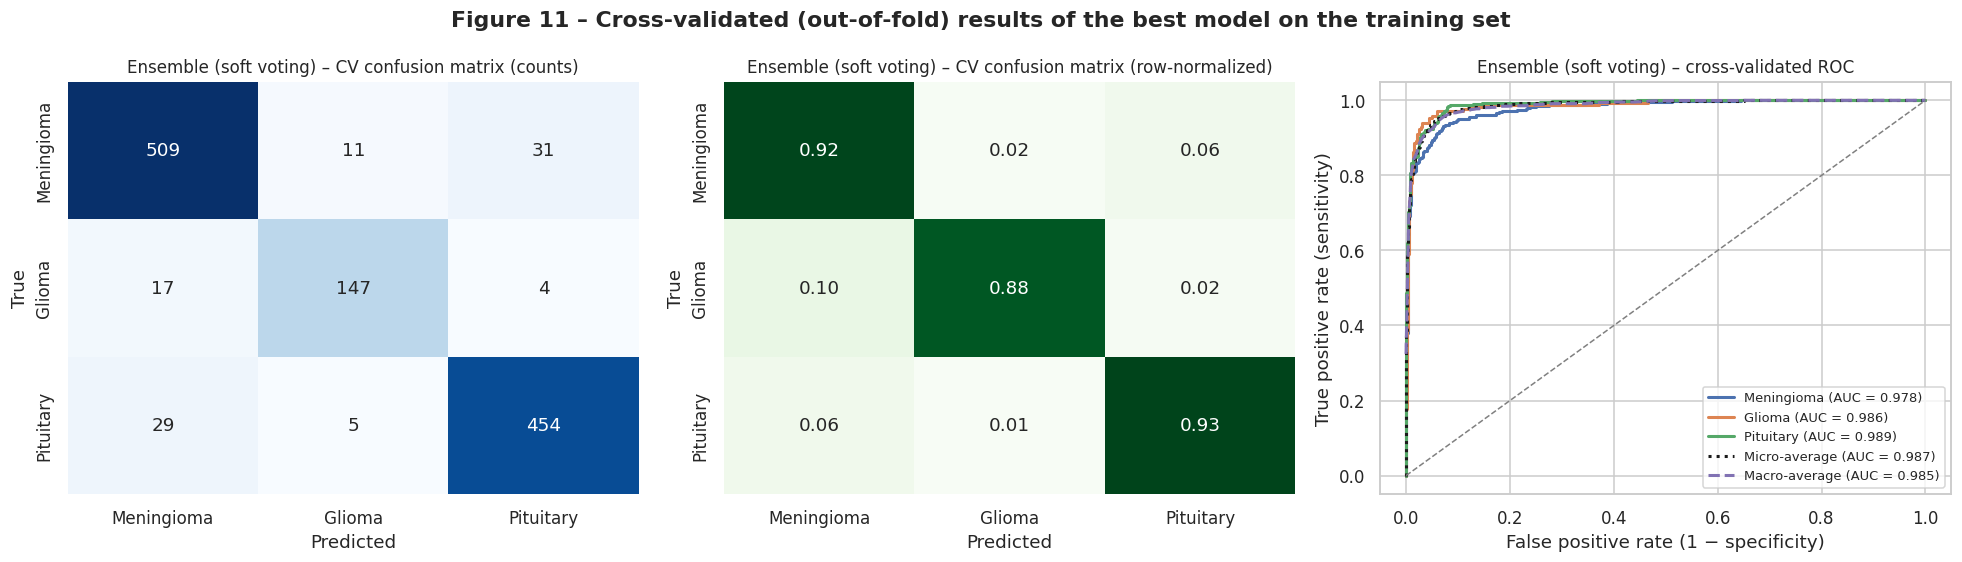

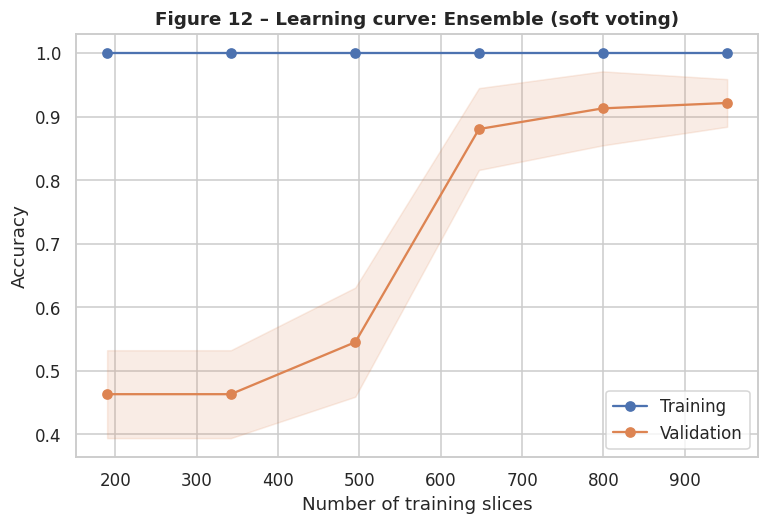

In [ ]:
def plot_cm(ax, y, pred, title, normalize=False, cmap="Blues"):
    cm = confusion_matrix(y, pred, labels=[0, 1, 2])
    data_ = cm / cm.sum(1, keepdims=True) if normalize else cm
    sns.heatmap(data_, annot=True, fmt=".2f" if normalize else "d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, annot_kws={"size": 12})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=11)

def plot_roc(ax, y, proba, title):
    Y = label_binarize(y, classes=[0, 1, 2]); fpr_all = np.linspace(0, 1, 200); tprs = []
    for k, name in enumerate(CLASS_ORDER):
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        ax.plot(fpr, tpr, color=CLASS_COLORS[name], lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
        tprs.append(np.interp(fpr_all, fpr, tpr))
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    ax.plot(fpr, tpr, "k:", lw=2, label=f"Micro-average (AUC = {auc(fpr, tpr):.3f})")
    ax.plot(fpr_all, np.mean(tprs, 0), "m--", lw=2, label=f"Macro-average (AUC = {auc(fpr_all, np.mean(tprs, 0)):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", lw=1, ls="--")
    ax.set_xlabel("False positive rate (1 − specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
    ax.set_title(title, fontsize=11); ax.legend(loc="lower right", fontsize=8.5)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
plot_cm(ax[0], y_train, oof_pred, f"{BEST} – CV confusion matrix (counts)")
plot_cm(ax[1], y_train, oof_pred, f"{BEST} – CV confusion matrix (row-normalized)", normalize=True, cmap="Greens")
plot_roc(ax[2], y_train, oof_proba[BEST], f"{BEST} – cross-validated ROC")
plt.suptitle("Figure 11 – Cross-validated (out-of-fold) results of the best model on the training set", fontweight="bold")
plt.tight_layout(); savefig("fig11_best_model_cv_cm_roc")

# Learning curve of the best model
sizes, tr_sc, va_sc = learning_curve(make_pipeline(clone(MODELS[BEST])), X_train, y_train, groups=g_train, cv=cv,
                                     train_sizes=np.linspace(0.2, 1.0, 6), scoring="accuracy", n_jobs=1,
                                     )
fig, ax = plt.subplots(figsize=(8, 5))
for sc, lab, col in [(tr_sc, "Training", "#4C72B0"), (va_sc, "Validation", "#DD8452")]:
    ax.plot(sizes, sc.mean(1), "o-", color=col, label=lab)
    ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=0.15)
ax.set_xlabel("Number of training slices"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title(f"Figure 12 – Learning curve: {BEST}", fontweight="bold")
savefig("fig12_learning_curve")

## 10. Test-set evaluation (unseen patients)
All seven models trained on the full training set are evaluated on the held-out test patients.

**Table 15 – Performance on the independent TEST set (slice level, macro-averaged)**

,Accuracy,Balanced Acc,Precision,Sensitivity (Recall),Specificity,F1-score,AUC (macro OvR),Cohen Kappa,MCC
Model,,,,,,,,,
Logistic Regression,0.9262,0.9191,0.9175,0.9191,0.9586,0.9180,0.9899,0.8756,0.8761
SVM (RBF),0.9446,0.9454,0.9513,0.9454,0.9675,0.9482,0.9923,0.9064,0.9065
KNN,0.9385,0.9085,0.9547,0.9085,0.9637,0.9276,0.9908,0.8952,0.8968
Random Forest,0.9508,0.9448,0.9561,0.9448,0.9721,0.9493,0.9920,0.9169,0.9187
XGBoost,0.9385,0.9421,0.9403,0.9421,0.9653,0.9404,0.9958,0.8965,0.8979
MLP,0.9415,0.9436,0.9489,0.9436,0.9660,0.9459,0.9940,0.9013,0.9018
Ensemble (soft voting),0.9538,0.9597,0.9583,0.9597,0.9736,0.9586,0.9944,0.9223,0.9230


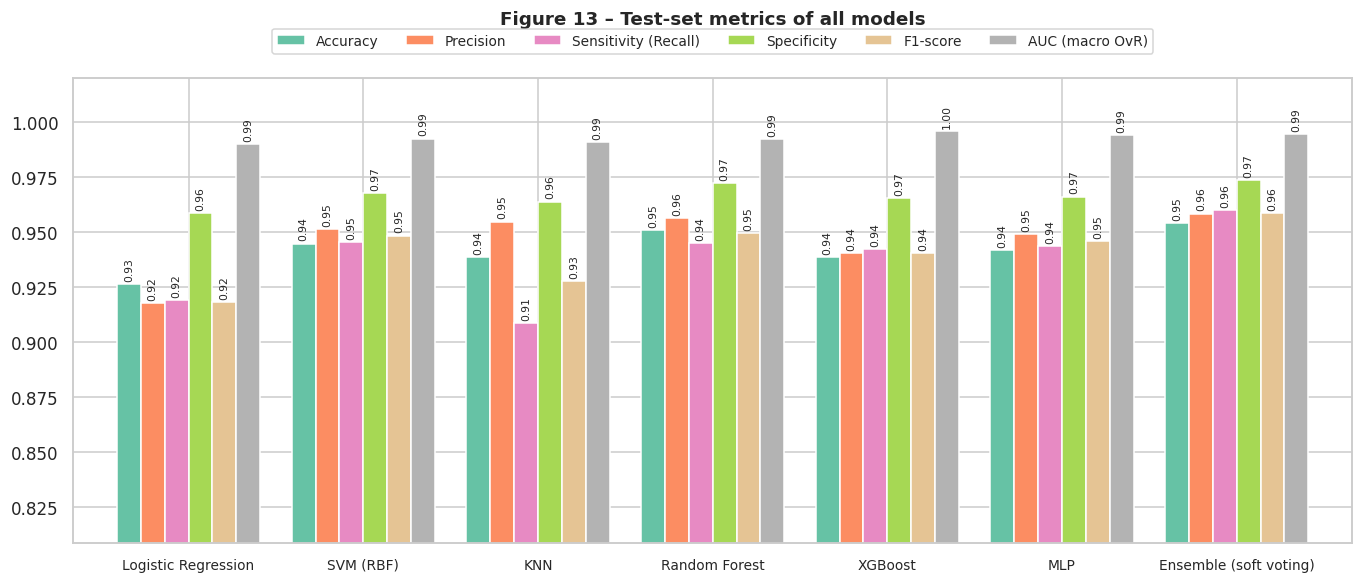

In [ ]:
test_rows, test_proba, test_pred = [], {}, {}
for name, pipe in fitted.items():
    test_proba[name] = pipe.predict_proba(X_test); test_pred[name] = test_proba[name].argmax(1)
    test_rows.append({"Model": name, **metrics_dict(y_test, test_pred[name], test_proba[name])})
test_table = pd.DataFrame(test_rows).set_index("Model")
display(Markdown("**Table 15 – Performance on the independent TEST set (slice level, macro-averaged)**"))
display(test_table.style.format("{:.4f}").highlight_max(color="#c7e9c0"))
savetab(test_table, "15_test_set_metrics")

fig, ax = plt.subplots(figsize=(15, 5.5))
cols = ["Accuracy", "Precision", "Sensitivity (Recall)", "Specificity", "F1-score", "AUC (macro OvR)"]
test_table[cols].plot.bar(ax=ax, rot=0, colormap="Set2", width=0.82)
ax.set_ylim(max(0, test_table[cols].values.min() - 0.1), 1.02); ax.set_xlabel("")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.12), fontsize=9); ax.tick_params(axis="x", labelsize=9)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, rotation=90, padding=2)
ax.set_title("Figure 13 – Test-set metrics of all models", fontweight="bold", pad=35)
savefig("fig13_test_metrics_comparison")

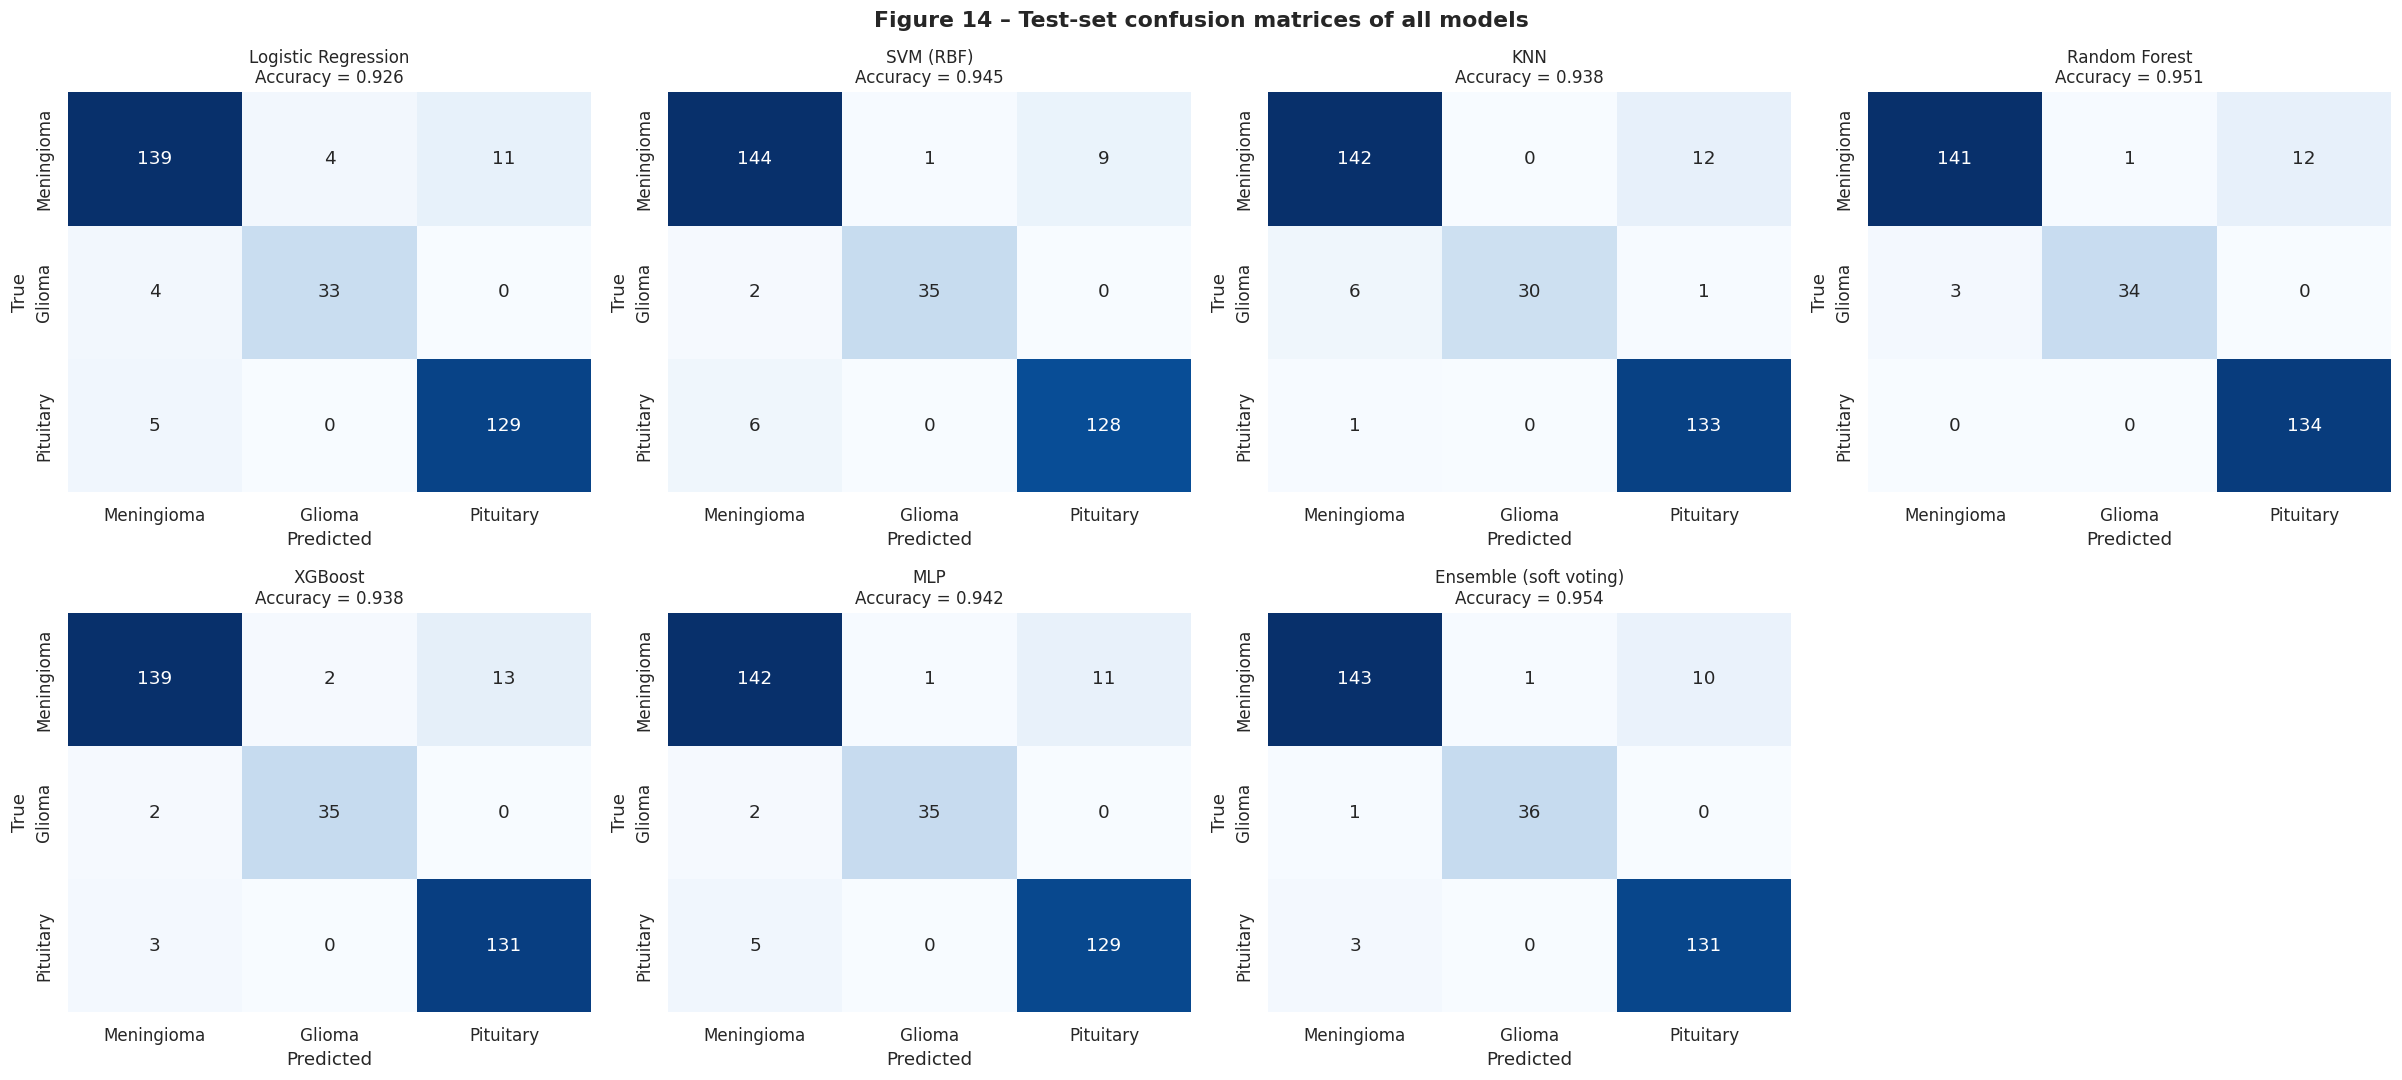

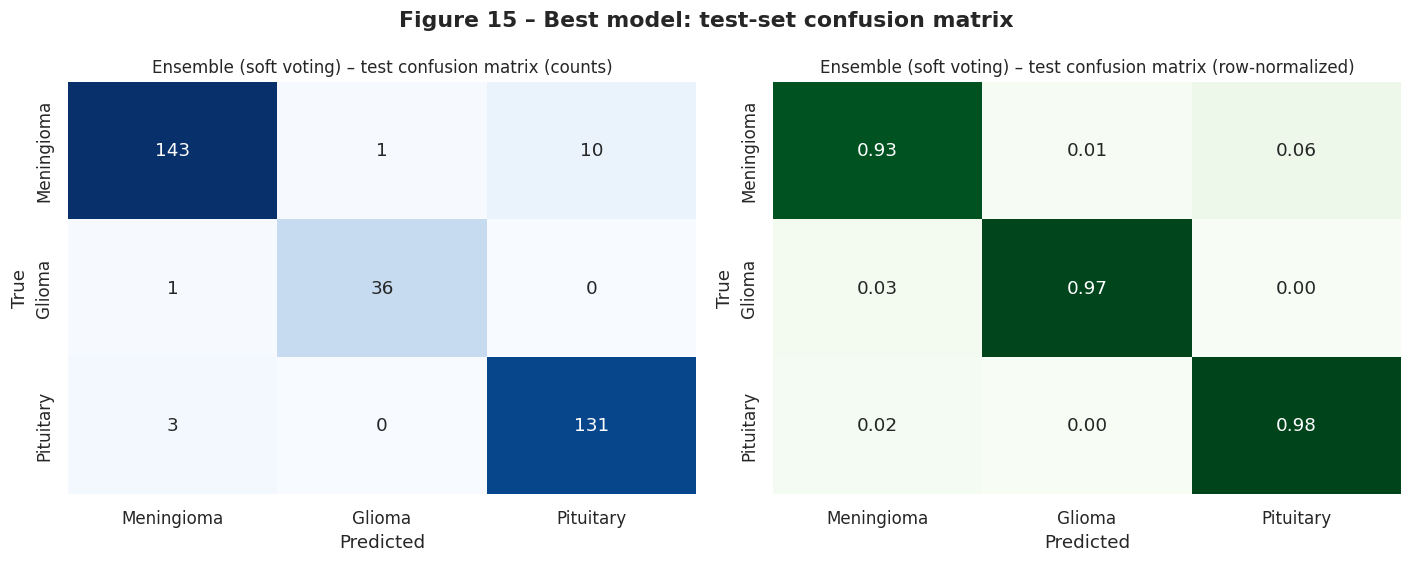

**Table 16 – Classification report of the best model (Ensemble (soft voting)) on the test set**

,precision,recall,f1-score,support
Meningioma,0.9728,0.9286,0.9502,154
Glioma,0.9730,0.9730,0.9730,37
Pituitary,0.9291,0.9776,0.9527,134
accuracy,0.9538,0.9538,0.9538,1
macro avg,0.9583,0.9597,0.9586,325
weighted avg,0.9548,0.9538,0.9538,325


**Table 17 – Per-class test performance of Ensemble (soft voting)**

,TP,FN,FP,TN,Sensitivity,Specificity,Precision (PPV),NPV,F1,AUC
Class,,,,,,,,,,
Meningioma,143,11,4,167,0.9286,0.9766,0.9728,0.9382,0.9502,0.9900
Glioma,36,1,1,287,0.9730,0.9965,0.9730,0.9965,0.9730,0.9985
Pituitary,131,3,10,181,0.9776,0.9476,0.9291,0.9837,0.9527,0.9947


In [ ]:
n = len(fitted)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for a in axes.flat[len(fitted):]: a.axis("off")
for a, name in zip(axes.flat, fitted):
    plot_cm(a, y_test, test_pred[name], f"{name}\nAccuracy = {accuracy_score(y_test, test_pred[name]):.3f}")
plt.suptitle("Figure 14 – Test-set confusion matrices of all models", fontweight="bold"); plt.tight_layout()
savefig("fig14_test_confusion_matrices_all")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
plot_cm(ax[0], y_test, test_pred[BEST], f"{BEST} – test confusion matrix (counts)")
plot_cm(ax[1], y_test, test_pred[BEST], f"{BEST} – test confusion matrix (row-normalized)", normalize=True, cmap="Greens")
plt.suptitle("Figure 15 – Best model: test-set confusion matrix", fontweight="bold"); plt.tight_layout()
savefig("fig15_best_model_test_cm")

rep = pd.DataFrame(classification_report(y_test, test_pred[BEST], target_names=CLASS_ORDER, output_dict=True, digits=4)).T
display(Markdown(f"**Table 16 – Classification report of the best model ({BEST}) on the test set**"))
display(rep.style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1-score": "{:.4f}", "support": "{:.0f}"}))
savetab(rep, "16_best_model_classification_report")

cm = confusion_matrix(y_test, test_pred[BEST], labels=[0, 1, 2]); Y = label_binarize(y_test, classes=[0, 1, 2]); per = []
for k, c in enumerate(CLASS_ORDER):
    tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
    per.append({"Class": c, "TP": tp, "FN": fn, "FP": fp, "TN": tn, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
                "Precision (PPV)": tp / (tp + fp) if tp + fp else 0, "NPV": tn / (tn + fn) if tn + fn else 0,
                "F1": 2 * tp / (2 * tp + fp + fn), "AUC": roc_auc_score(Y[:, k], test_proba[BEST][:, k])})
per = pd.DataFrame(per).set_index("Class")
display(Markdown(f"**Table 17 – Per-class test performance of {BEST}**"))
display(per.style.format({c: "{:.4f}" for c in ["Sensitivity", "Specificity", "Precision (PPV)", "NPV", "F1", "AUC"]}))
savetab(per, "17_best_model_per_class")

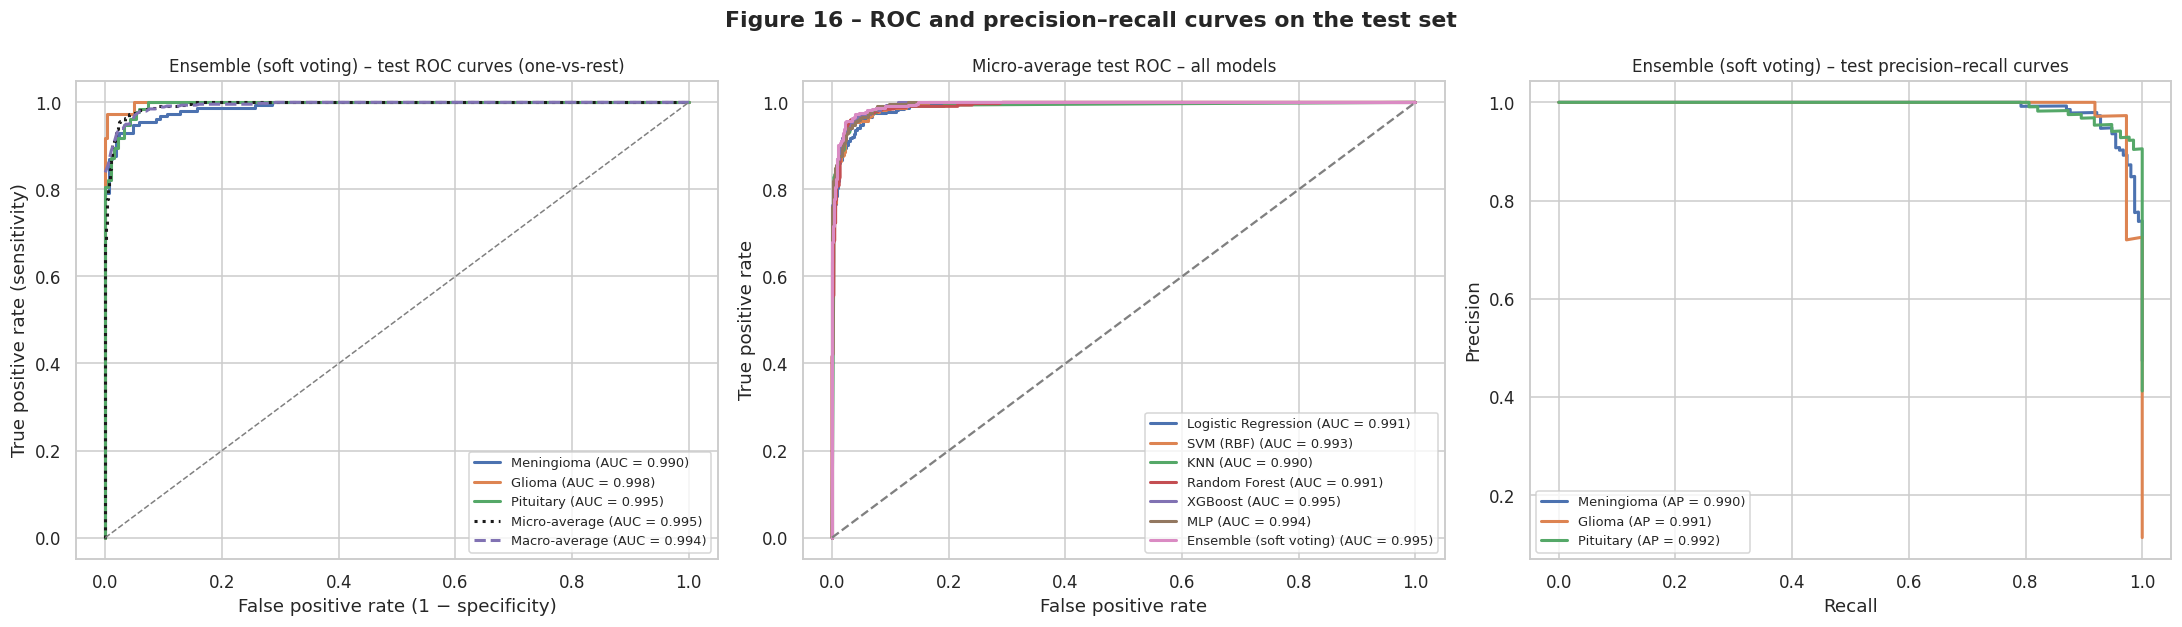

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.8))
plot_roc(ax[0], y_test, test_proba[BEST], f"{BEST} – test ROC curves (one-vs-rest)")

for name in fitted:
    Yb = label_binarize(y_test, classes=[0, 1, 2]); fpr, tpr, _ = roc_curve(Yb.ravel(), test_proba[name].ravel())
    ax[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
ax[1].plot([0, 1], [0, 1], color="grey", ls="--"); ax[1].legend(loc="lower right", fontsize=8.5)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("Micro-average test ROC – all models", fontsize=11)

Yb = label_binarize(y_test, classes=[0, 1, 2])
for k, c in enumerate(CLASS_ORDER):
    pr, rc, _ = precision_recall_curve(Yb[:, k], test_proba[BEST][:, k])
    ax[2].plot(rc, pr, lw=2, color=CLASS_COLORS[c], label=f"{c} (AP = {average_precision_score(Yb[:, k], test_proba[BEST][:, k]):.3f})")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title(f"{BEST} – test precision–recall curves", fontsize=11)
ax[2].legend(loc="lower left", fontsize=8.5)
plt.suptitle("Figure 16 – ROC and precision–recall curves on the test set", fontweight="bold"); plt.tight_layout()
savefig("fig16_test_roc_pr")

**Table 18 – Patient-level test performance (mean slice probability per patient)**

,Patients,Accuracy,Balanced Acc,Precision,Sensitivity (Recall),Specificity,F1-score,AUC (macro OvR),Cohen Kappa,MCC
Ensemble (soft voting) – patient level,33,0.9697,0.9792,0.9762,0.9792,0.9833,0.9769,1.0000,0.9493,0.9508


**Table 19 – Accuracy: training vs cross-validation vs test**

,Training (re-substitution),Cross-validation,Test
Logistic Regression,0.9909,0.8917,0.9262
SVM (RBF),0.9992,0.9109,0.9446
KNN,1.0000,0.8681,0.9385
Random Forest,1.0000,0.8974,0.9508
XGBoost,1.0000,0.9191,0.9385
MLP,0.9867,0.9042,0.9415
Ensemble (soft voting),1.0000,0.9206,0.9538


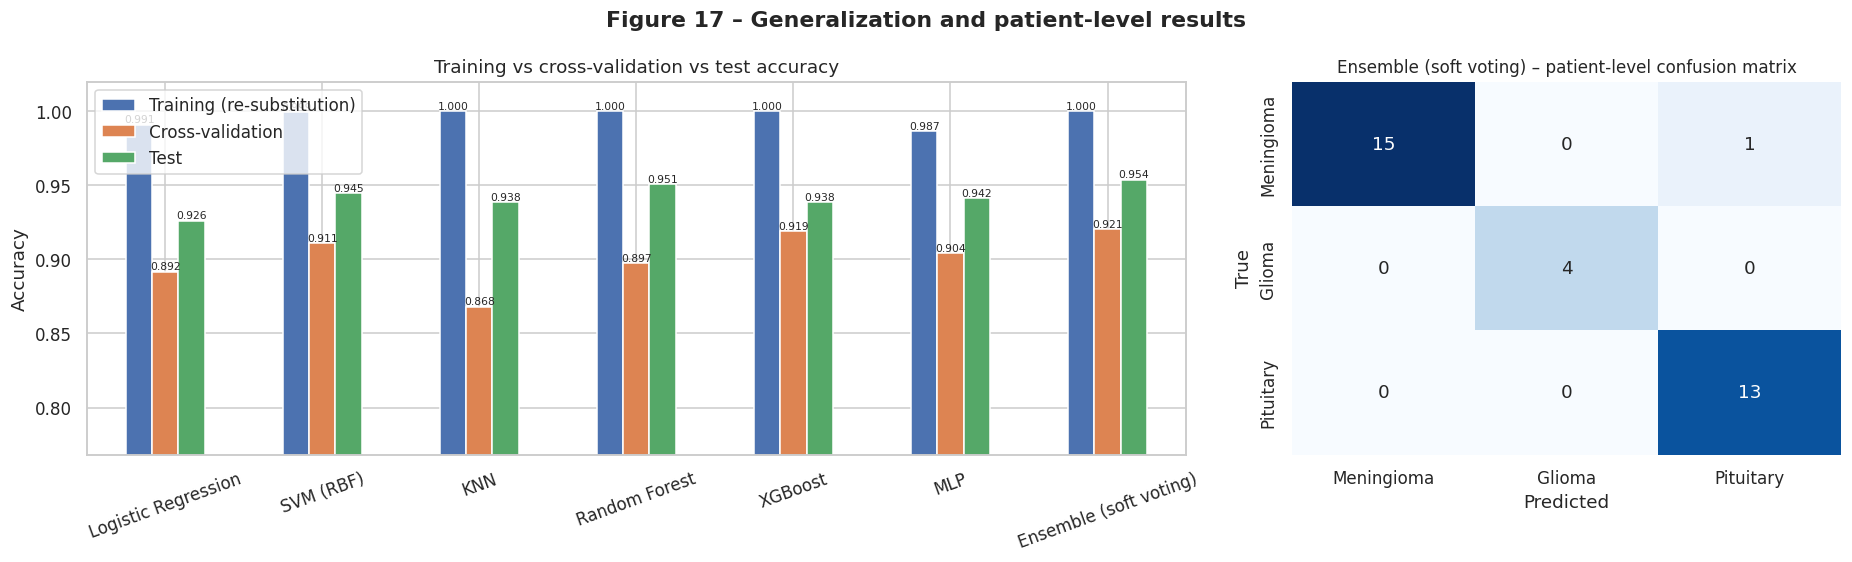

In [ ]:
# Patient-level evaluation: average the slice probabilities of each test patient
pat = pd.DataFrame(test_proba[BEST], columns=CLASS_ORDER); pat["PID"] = g_test; pat["y"] = y_test
pat = pat.groupby("PID").agg({**{c: "mean" for c in CLASS_ORDER}, "y": "first"})
pat_pred = pat[CLASS_ORDER].values.argmax(1)
pat_metrics = pd.DataFrame([metrics_dict(pat.y.values, pat_pred, pat[CLASS_ORDER].values)], index=[f"{BEST} – patient level"])
pat_metrics.insert(0, "Patients", len(pat))
display(Markdown("**Table 18 – Patient-level test performance (mean slice probability per patient)**"))
display(pat_metrics.style.format({c: "{:.4f}" for c in pat_metrics.columns if c != "Patients"}))
savetab(pat_metrics, "18_patient_level_metrics")

# Generalization summary: training vs cross-validation vs test
gen = pd.DataFrame({"Training (re-substitution)": train_table["Accuracy"],
                    "Cross-validation": {n: cv_folds[n]["test_Accuracy"].mean() for n in MODELS},
                    "Test": test_table["Accuracy"]}).reindex(MODELS.keys())
display(Markdown("**Table 19 – Accuracy: training vs cross-validation vs test**")); display(gen.round(4))
savetab(gen, "19_generalization_summary")

fig, ax = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [2, 1]})
gen.plot.bar(ax=ax[0], rot=20, color=["#4C72B0", "#DD8452", "#55A868"])
ax[0].set_ylim(max(0, gen.values.min() - 0.1), 1.02); ax[0].set_ylabel("Accuracy"); ax[0].set_xlabel("")
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.3f", fontsize=7)
ax[0].set_title("Training vs cross-validation vs test accuracy")
plot_cm(ax[1], pat.y.values, pat_pred, f"{BEST} – patient-level confusion matrix")
plt.suptitle("Figure 17 – Generalization and patient-level results", fontweight="bold"); plt.tight_layout()
savefig("fig17_generalization_patient_level")

## 11. Model interpretation

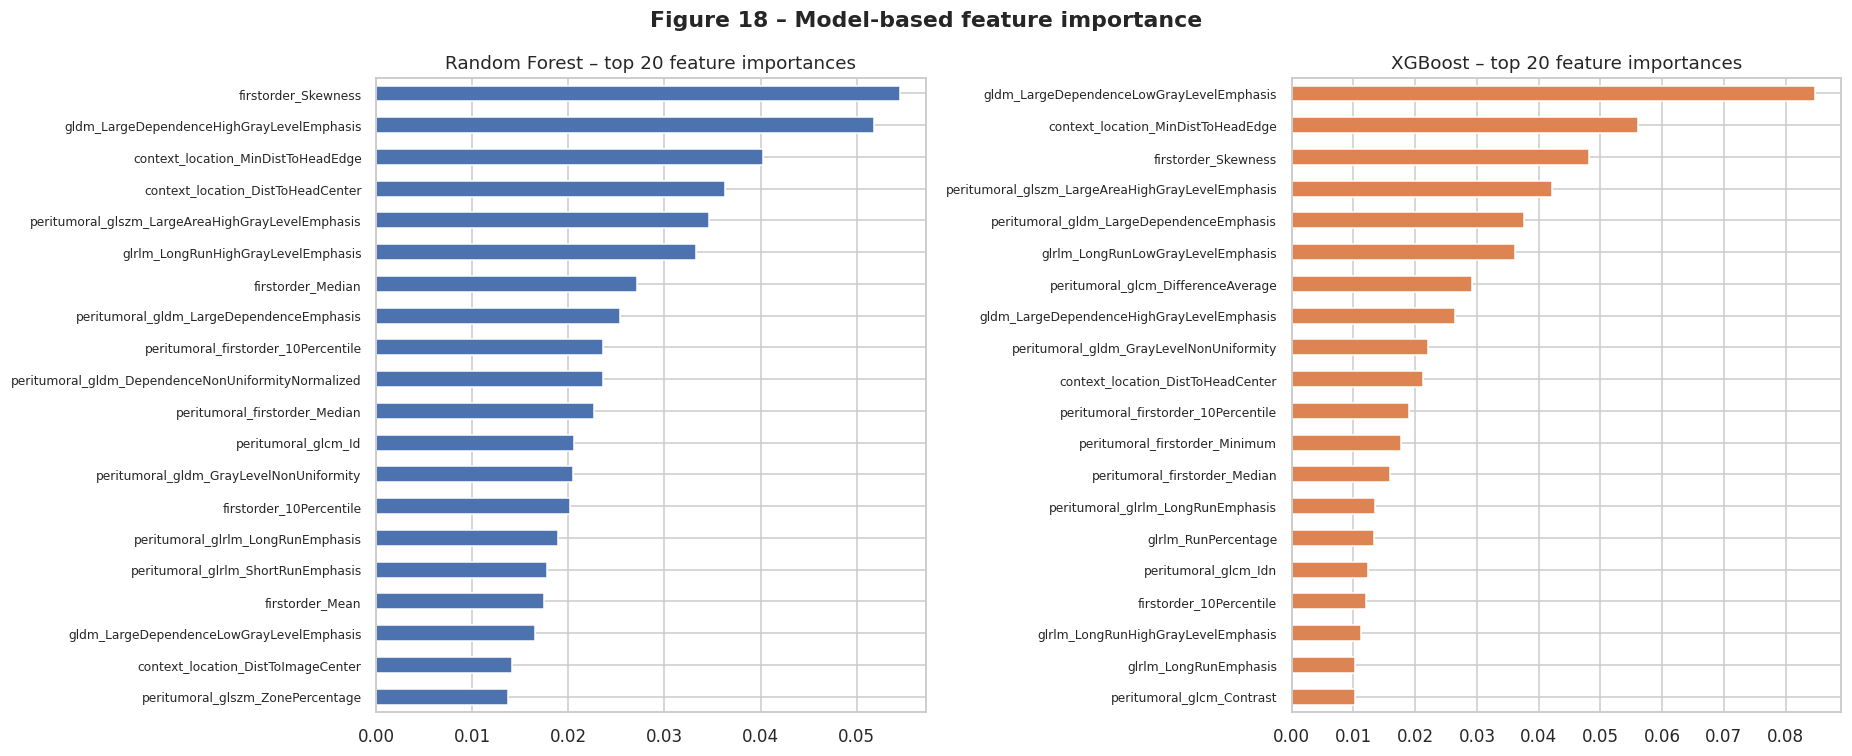

**Table 20 – Permutation importance of Ensemble (soft voting) on the test set (top 15)**

,Feature,Mean drop in F1,SD
0,original_firstorder_Skewness,0.0138,0.0058
1,peritumoral_glrlm_RunVariance,0.0130,0.0015
2,peritumoral_glrlm_ShortRunEmphasis,0.0128,0.0038
3,original_firstorder_Median,0.0127,0.0051
4,original_gldm_LowGrayLevelEmphasis,0.0123,0.0022
5,peritumoral_firstorder_Median,0.0122,0.0036
6,original_firstorder_Mean,0.0120,0.0033
7,peritumoral_glrlm_LongRunEmphasis,0.0119,0.0020
8,peritumoral_gldm_LargeDependenceEmphasis,0.0112,0.0020
9,original_glcm_MCC,0.0111,0.0017


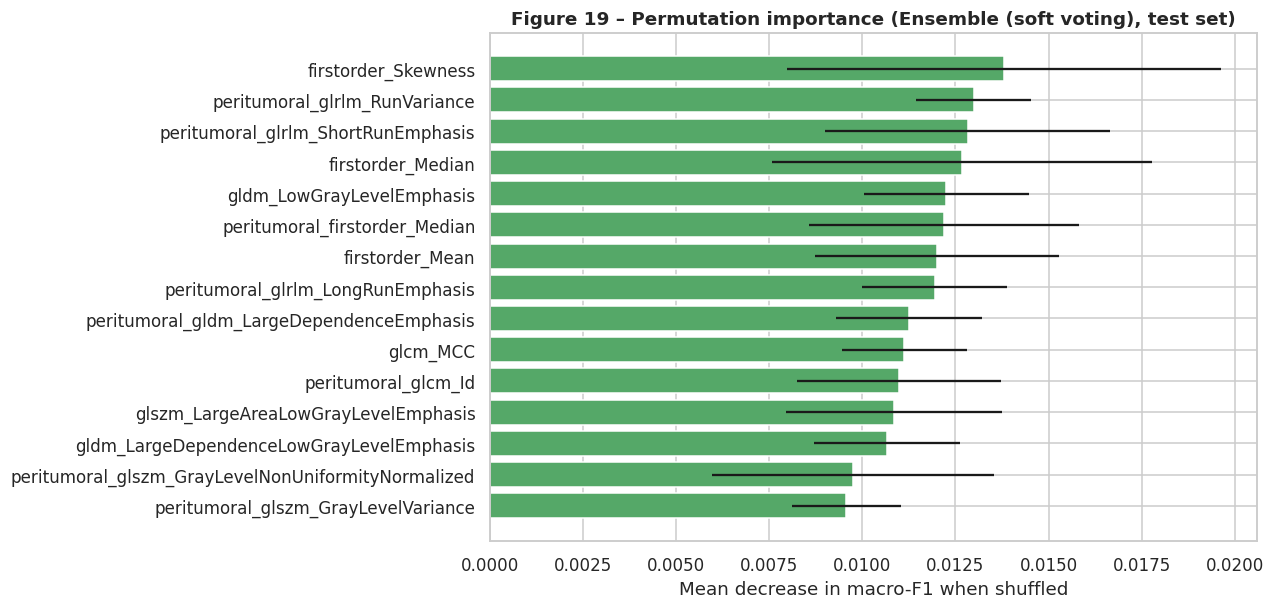

In [ ]:
sel_names = lambda pipe: np.array(FEATURES)[pipe.named_steps["var"].get_support()][pipe.named_steps["corr"].support_][pipe.named_steps["select"].support_]
short = lambda arr: [f.replace("original_", "") for f in arr]

fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for a, name in zip(ax, ["Random Forest", "XGBoost"]):
    p = fitted[name]; imp = pd.Series(p.named_steps["clf"].feature_importances_, index=short(sel_names(p))).sort_values().tail(20)
    imp.plot.barh(ax=a, color="#4C72B0" if name == "Random Forest" else "#DD8452")
    a.set_title(f"{name} – top 20 feature importances"); a.tick_params(axis="y", labelsize=8)
plt.suptitle("Figure 18 – Model-based feature importance", fontweight="bold"); plt.tight_layout()
savefig("fig18_feature_importance")

# Permutation importance of the best model on the test set
best_pipe = fitted[BEST]
Xt_sel = Pipeline(best_pipe.steps[:-1]).transform(X_test)
pi = permutation_importance(best_pipe.named_steps["clf"], Xt_sel, y_test, n_repeats=10, random_state=SEED, scoring="f1_macro", n_jobs=-1)
pi_df = pd.DataFrame({"Feature": sel_names(best_pipe), "Mean drop in F1": pi.importances_mean, "SD": pi.importances_std})
pi_df = pi_df[pi_df["Mean drop in F1"] != 0].sort_values("Mean drop in F1", ascending=False)
display(Markdown(f"**Table 20 – Permutation importance of {BEST} on the test set (top 15)**"))
display(pi_df.head(15).reset_index(drop=True).style.format({"Mean drop in F1": "{:.4f}", "SD": "{:.4f}"}))
savetab(pi_df, "20_permutation_importance", index=False)
top_pi = pi_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(short(top_pi.Feature), top_pi["Mean drop in F1"], xerr=top_pi.SD, color="#55A868")
ax.set_xlabel("Mean decrease in macro-F1 when shuffled"); ax.set_title(f"Figure 19 – Permutation importance ({BEST}, test set)", fontweight="bold")
savefig("fig19_permutation_importance")

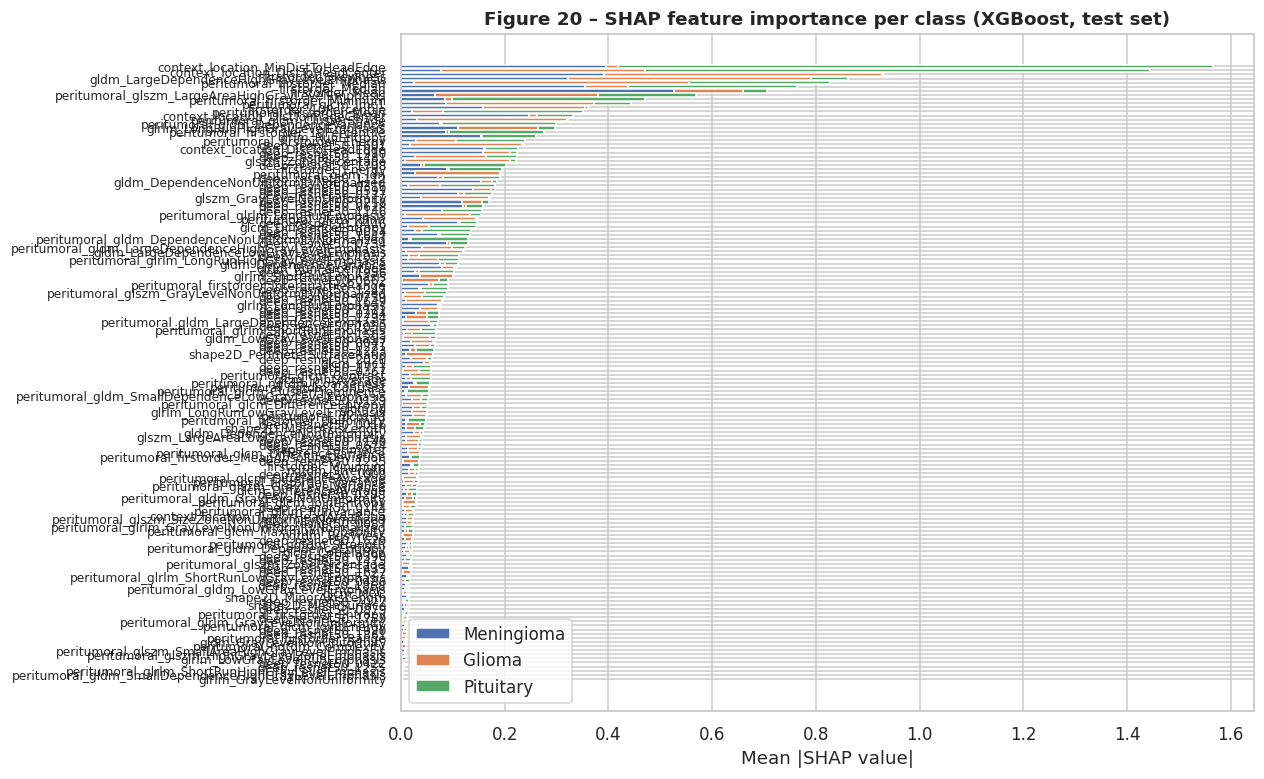

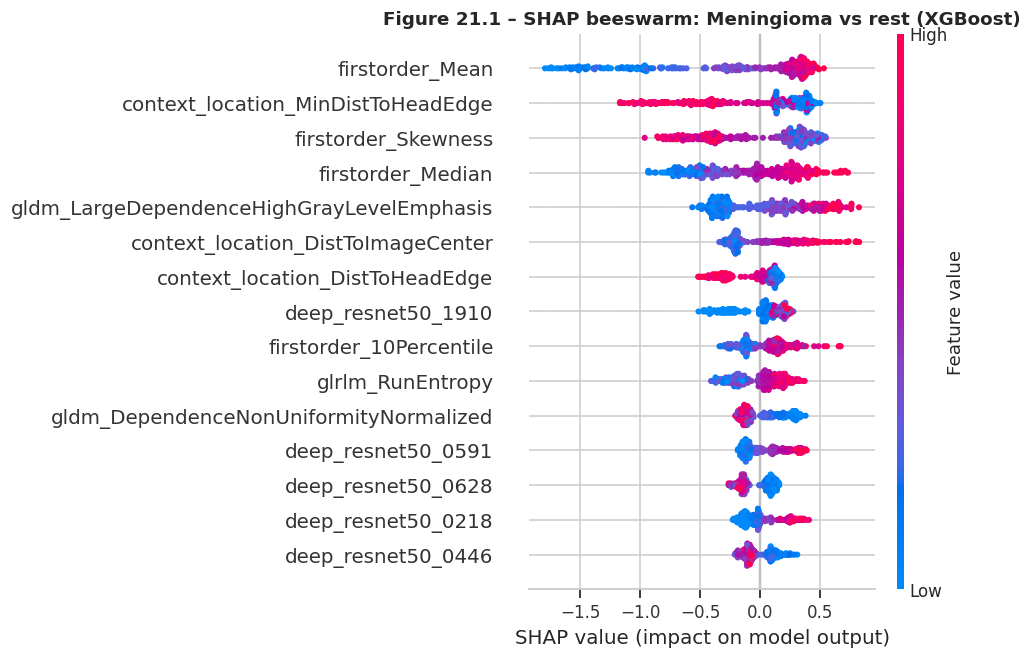

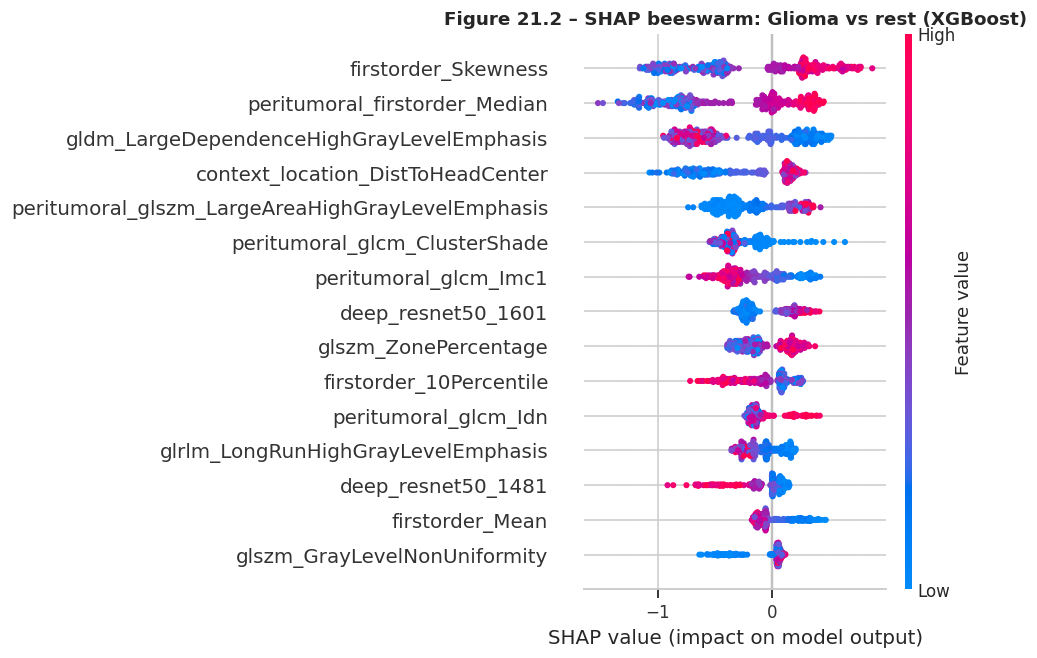

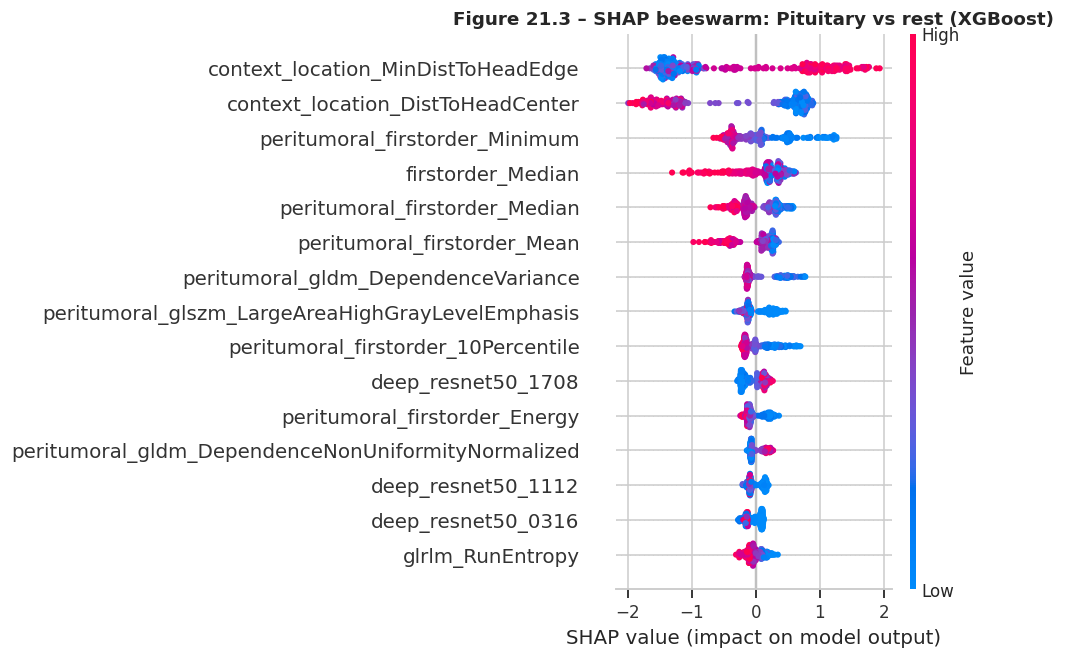

In [ ]:
import shap
xgb_pipe = fitted["XGBoost"]
Xt_test = Pipeline(xgb_pipe.steps[:-1]).transform(X_test)
fnames = short(sel_names(xgb_pipe))
sv = shap.TreeExplainer(xgb_pipe.named_steps["clf"]).shap_values(Xt_test)
sv = [sv[:, :, k] for k in range(sv.shape[2])] if isinstance(sv, np.ndarray) and sv.ndim == 3 else list(sv)

mean_abs = pd.DataFrame({c: np.abs(sv[k]).mean(0) for k, c in enumerate(CLASS_ORDER)}, index=fnames)
mean_abs["Total"] = mean_abs.sum(1); mean_abs = mean_abs.sort_values("Total")
fig, ax = plt.subplots(figsize=(10, 8))
left = np.zeros(len(mean_abs))
for c in CLASS_ORDER:
    ax.barh(mean_abs.index, mean_abs[c], left=left, color=CLASS_COLORS[c], label=c); left += mean_abs[c].values
ax.set_xlabel("Mean |SHAP value|"); ax.legend(); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Figure 20 – SHAP feature importance per class (XGBoost, test set)", fontweight="bold")
savefig("fig20_shap_bar")
savetab(mean_abs.iloc[::-1], "21_shap_mean_abs")

for k, c in enumerate(CLASS_ORDER):
    shap.summary_plot(sv[k], Xt_test, feature_names=fnames, max_display=15, show=False, plot_size=(9, 6))
    plt.title(f"Figure 21.{k+1} – SHAP beeswarm: {c} vs rest (XGBoost)", fontweight="bold")
    savefig(f"fig21_{k+1}_shap_beeswarm_{c.lower()}")

## 12. Final summary and download

In [ ]:
best_test = test_table.loc[BEST]
final = pd.DataFrame({
    "Item": ["Dataset", "Slices / patients", "Train / test patients", "Features extracted (radiomics + extra)", "Features selected",
             "Best model (by CV F1)", "CV accuracy (mean ± SD)", "Test accuracy", "Test macro-F1", "Test macro AUC",
             "Test sensitivity / specificity", "Patient-level test accuracy"],
    "Value": ["Figshare brain tumor (CE-T1 MRI)", f"{len(data)} / {data.PID.nunique()}",
              f"{train.PID.nunique()} / {test.PID.nunique()}", len(FEATURES), len(selected), BEST,
              f"{cv_folds[BEST]['test_Accuracy'].mean():.4f} ± {cv_folds[BEST]['test_Accuracy'].std():.4f}",
              f"{best_test['Accuracy']:.4f}", f"{best_test['F1-score']:.4f}", f"{best_test['AUC (macro OvR)']:.4f}",
              f"{best_test['Sensitivity (Recall)']:.4f} / {best_test['Specificity']:.4f}",
              f"{pat_metrics['Accuracy'].iloc[0]:.4f}"]})
display(Markdown("**Table 23 – Final results summary**")); display(final.set_index("Item"))
savetab(final, "23_final_summary", index=False)

# All tables in one Excel workbook
with pd.ExcelWriter(os.path.join(RESULTS_DIR, "all_results_tables.xlsx")) as xw:
    for f in sorted(glob.glob(os.path.join(TAB_DIR, "*.csv"))):
        name = os.path.basename(f)[:-4][:31]
        if "all_radiomic_features" in name: continue
        pd.read_csv(f).to_excel(xw, sheet_name=name, index=False)

archive = shutil.make_archive(os.path.join(WORK_DIR, "radiomics_results"), "zip", RESULTS_DIR)
print(f"Saved {len(glob.glob(FIG_DIR + '/*.png'))} figures and {len(glob.glob(TAB_DIR + '/*.csv'))} tables to {RESULTS_DIR}")
print("Zip archive:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

**Table 23 – Final results summary**

,Value
Item,
Dataset,Figshare brain tumor (CE-T1 MRI)
Slices / patients,1532 / 163
Train / test patients,130 / 33
Features extracted (radiomics + extra),2250
Features selected,150
Best model (by CV F1),Ensemble (soft voting)
CV accuracy (mean ± SD),0.9206 ± 0.0377
Test accuracy,0.9538
Test macro-F1,0.9586


Saved 24 figures and 23 tables to /content/drive/MyDrive/radiomics_results
Zip archive: /content/figshare_work/radiomics_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>